# Cars 4 You Prediction

### Group 70
- Duarte Neves 20221880
- Ricardo Trindade 20222039
- Rodrigo Amaral 20221943

## Abstract

The Cars 4 You Prediction project was created to improve and speed up the vehicle valuation process for Cars 4 You, an online car resale platform. Previously, the company relied on manual inspections by mechanics, which caused delays and long waiting times for customers. To overcome these challenges, our project is focused on developing a predictive model that can accurately estimate a car’s fair market price based solely on user-provided information, reducing the need for manual checks while ensuring transparency and reliability.

Using Cars 4 You’s 2020 dataset, which includes variables such as brand, model, year, mileage, fuel type, transmission, tax, engine size, and ownership history, a complete data pipeline was designed. Data preprocessing involved engineering features to enhance our model's predictive performance, handling categorical features by using different encoding methods, and performing iterative imputation to estimate missing values based on correlations among features. Regarding feature engineering, we created new informative variables, including efficiency score (mpg-to-engine ratio), mileage per year, tax per engine size, and ownership intensity, while categorical features were encoded using frequency and target encoding techniques.

Furthermore, our feature selection process combined several methods such as Recursive Feature Elimination, Lasso regression, Mutual Information, and correlation analysis with the objective of retaining only the most relevant predictors. Afterwards, multiple regression models were benchmarked, including Linear Regression, KNN, Decision Trees, Random Forest, Extra Trees, Gradient Boosting, and Multi-Layer Perceptron. Model performance was compared using Mean Absolute Error (MAE), and when performing hyperparameter tuning using Optuna's Random Search, we added logic related to the overfit gap where larger gaps incurred greater penalties and smaller gaps incurred smaller penalties. This helped ensure that our models generalized well and minimized overfitting.

After fine-tuning, we implemented an ensemble approach which delivered the best performance (MAE on validation was 1224.48; MAE on train was 980.10; Gap between train and validation was 244.38).Through this ensemble we were able to reduce both validation set performance and overfit gap which makes our model not only better at predicting but also better at generalize. We then applied the same procedures to test data and deployed the final model to generate predictions for this dataset.

To finalize our project, we created an interactive Python interface that allows users to input vehicle details and instantly receive a predicted price along with a predicted price confidence interval that ensures the actual market price falls within this interval. Overall, the project demonstrates how machine learning can modernize and accelerate the car resale process, offering a scalable, data-driven solution for faster and more reliable price evaluations.

#  Table of Contents
- [ Functions](#-functions)
- [ Data Integration](#-data-integration)
- [ Data Exploration](#-data-exploration)
- [ Data Modification](#-data-modification)
  - [ Feature Engineering](#-feature-engineering) 
  - [ Data Preparation](#-data-preparation)
  - [ Feature Selection](#-feature-selection)
- [ Modeling and Assessment](#-modeling-and-assessment)
- [ Model Deployment](#-model-deployment)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from math import ceil

from rapidfuzz import process

from scipy import stats
from scipy.stats import chi2_contingency, loguniform, randint

from sklearn.preprocessing import RobustScaler, MinMaxScaler, PowerTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif,f_regression,SelectKBest
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, median_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor,GradientBoostingRegressor
from sklearn.feature_selection import RFE,mutual_info_regression
from sklearn.neural_network import MLPRegressor
from sklearn.impute import KNNImputer
from sklearn.linear_model import LassoCV
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import ElasticNet
from scipy.optimize import minimize


import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from IPython.display import Image

import optuna
from optuna.pruners import MedianPruner

In [2]:
%load_ext autotime

time: 93.3 μs (started: 2025-12-16 16:50:55 +00:00)


In [3]:
np.random.seed(42)

time: 573 μs (started: 2025-12-16 16:50:55 +00:00)


## Functions

*All created functions used for the project*

In [4]:
def fill_brand_from_model(row):
    """
    In case a car has a model but the brand is missing, the brand will be imputed based on the model
    """
    if pd.isna(row['Brand']) and pd.notna(row['model']):
        return brand_model_map.get(row['model'], np.nan)
    return row['Brand']

time: 434 μs (started: 2025-12-16 16:50:55 +00:00)


In [5]:
def fuzzy_match_model(model):
    result = process.extractOne(model, canonical_models)
    if result is None:
        return model
    match, score, _ = result
    return match if score > 85 else model

time: 424 μs (started: 2025-12-16 16:50:55 +00:00)


In [6]:
def plot_multiple_boxplots(data, feats, title="Numeric Variables' Box Plots"):

    fig, axes = plt.subplots(2, ceil(len(feats) / 2), figsize=(30, 11))

    for ax, feat in zip(axes.flatten(), feats):
      sns.boxplot(x=data[feat], ax=ax)
      ax.set_title(feat)


    plt.suptitle(title)

    plt.show()

    return

time: 622 μs (started: 2025-12-16 16:50:55 +00:00)


In [7]:
def outlier_percentage_iqr(df, columns=None):
    if columns is None:
        columns = df.select_dtypes(include=np.number).columns

    outlier_stats = []

    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        # Count outliers
        lower_out = (df[col] < lower).sum()
        upper_out = (df[col] > upper).sum()
        total_out = lower_out + upper_out
        total_n = df[col].notna().sum()

        outlier_stats.append({
            'Variable': col,
            '% Lower Outliers': 100 * lower_out / total_n,
            '% Upper Outliers': 100 * upper_out / total_n,
            '% Total Outliers': 100 * total_out / total_n
        })

    return pd.DataFrame(outlier_stats).sort_values('% Total Outliers', ascending=False).reset_index(drop=True)

time: 3.12 ms (started: 2025-12-16 16:50:55 +00:00)


In [8]:
def compute_iqr_limits(df):
    """Compute lower and upper IQR limits for each numeric column"""
    limits = {}
    for col in df.select_dtypes(include="number"):
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        limits[col] = (lower, upper)
    return limits

time: 569 μs (started: 2025-12-16 16:50:55 +00:00)


In [9]:
def apply_iqr_winsorize(df, limits):
    """Clip values based on precomputed limits"""
    df_wins = df.copy()
    for col, (lower, upper) in limits.items():
        df_wins[col] = df_wins[col].clip(lower, upper)
    return df_wins

time: 925 μs (started: 2025-12-16 16:50:55 +00:00)


In [10]:
def plot_multiple_histplots(data, feats, title="Numeric Variables' Box Plots"):

    fig, axes = plt.subplots(2, ceil(len(feats) / 2), figsize=(30, 11))

    for ax, feat in zip(axes.flatten(), feats):
      sns.histplot(x=data[feat], bins=30, ax=ax)
      ax.set_title(feat)


    plt.suptitle(title)

    plt.show()

    return

time: 571 μs (started: 2025-12-16 16:50:55 +00:00)


In [11]:
def cor_heatmap(cor):
    plt.figure(figsize=(18,16))
    sns.heatmap(data = cor, annot = True, cmap = plt.cm.Reds, fmt='.1')
    plt.show()

time: 382 μs (started: 2025-12-16 16:50:55 +00:00)


In [12]:
def plot_importance(coef,name):
    imp_coef = coef.sort_values()
    plt.figure(figsize=(8,10))
    imp_coef.plot(kind = "barh")
    plt.title("Feature importance using " + name + " Model")
    plt.show()

time: 674 μs (started: 2025-12-16 16:50:55 +00:00)


In [13]:
def calculate_metrics(y_pred_train, y_pred_val, model_name="Model"):
    """
    Calculate and display all regression metrics.

    """
    
    def adj_r2(r2, n, p):
        return 1 - (1 - r2) * (n - 1) / (n - p - 1)
    
    # Get dimensions
    n_t = len(y_train)
    n_v = len(y_val)
    p_t = X_train.shape[1] if hasattr(X_train, 'shape') else len(X_train.columns)
    p_v = X_val.shape[1] if hasattr(X_val, 'shape') else len(X_val.columns)
    
    # Calculate metrics
    r2_t = r2_score(y_train, y_pred_train)
    r2_v = r2_score(y_val, y_pred_val)
    ar2_t = adj_r2(r2_t, n_t, p_t)
    ar2_v = adj_r2(r2_v, n_v, p_v)
    mae_t = mean_absolute_error(y_train, y_pred_train)
    mae_v = mean_absolute_error(y_val, y_pred_val)
    mse_t = mean_squared_error(y_train, y_pred_train)
    mse_v = mean_squared_error(y_val, y_pred_val)
    rmse_t = root_mean_squared_error(y_train, y_pred_train)
    rmse_v = root_mean_squared_error(y_val, y_pred_val)
    medae_t = median_absolute_error(y_train, y_pred_train)
    medae_v = median_absolute_error(y_val, y_pred_val)
    mape_t = mean_absolute_percentage_error(y_train, y_pred_train)
    mape_v = mean_absolute_percentage_error(y_val, y_pred_val)


    diff_mae = mae_v - mae_t
    pct_diff_mae = (diff_mae / mae_t) * 100
    
    # Display results
    print("=" * 60)
    print(f"{model_name.upper()} METRICS")
    print("=" * 60)
    print("\nTRAIN SET METRICS:")
    print(f"  R² Score:              {r2_t:.4f}")
    print(f"  Adjusted R² Score:     {ar2_t:.4f}")
    print(f"  MAE:                   {mae_t:.4f}")
    print(f"  MSE:                   {mse_t:.4f}")
    print(f"  RMSE:                  {rmse_t:.4f}")
    print(f"  Median AE:             {medae_t:.4f}")
    print(f"  MAPE:                  {mape_t:.4f}")
    
    print("\nVALIDATION SET METRICS:")
    print(f"  R² Score:              {r2_v:.4f}")
    print(f"  Adjusted R² Score:     {ar2_v:.4f}")
    print(f"  MAE:                   {mae_v:.4f}")
    print(f"  MSE:                   {mse_v:.4f}")
    print(f"  RMSE:                  {rmse_v:.4f}")
    print(f"  Median AE:             {medae_v:.4f}")
    print(f"  MAPE:                  {mape_v:.4f}")

    print("\n" + "=" * 60)
    print("MAE COMPARISON")
    print("=" * 60)
    print(f"  Train MAE:             {mae_t:.4f}")
    print(f"  Validation MAE:        {mae_v:.4f}")
    print(f"  Difference:            {diff_mae:.4f}")
    print(f"  % Difference:          {pct_diff_mae:.2f}%")

time: 3.45 ms (started: 2025-12-16 16:50:55 +00:00)


In [14]:
def KNN_RS(trial):
    # Hyperparameters
    n_neighbors = trial.suggest_int("n_neighbors", 3, 50)
    weights = trial.suggest_categorical("weights", ["uniform", "distance"])
    p = trial.suggest_int("p", 1, 2)
    leaf_size = trial.suggest_int("leaf_size", 10, 50)

    # Model
    model = KNeighborsRegressor(
        n_neighbors=n_neighbors,
        weights=weights,
        p=p,
        leaf_size=leaf_size,
        n_jobs=-1
    )

    # Fit model
    model.fit(X_train, y_train)

    # Predictions
    preds_train = model.predict(X_train)
    preds_val   = model.predict(X_val)

    # Compute MAE
    mae_train = mean_absolute_error(y_train, preds_train)
    mae_val   = mean_absolute_error(y_val, preds_val)

    overfit_gap = abs(mae_val - mae_train)

    # Save MAEs for inspection
    trial.set_user_attr("train_mae", mae_train)
    trial.set_user_attr("val_mae", mae_val)
    trial.set_user_attr("overfit_gap", overfit_gap)

    # Custom objective: validation MAE + lambda * train/val gap
    # Penalize overfitting with adaptive penalty
    threshold = 300
    lambda_ = 0.6
    
    if overfit_gap > threshold:
        penalty = lambda_ * overfit_gap
    elif overfit_gap > 0:
        penalty = (lambda_ / 2) * overfit_gap
    else:
        # No penalty if model generalizes well (val better than train)
        penalty = 0
    
    objective_value = mae_val + penalty
    
    return objective_value

time: 3.27 ms (started: 2025-12-16 16:50:55 +00:00)


In [15]:
def DT_RS(trial):
    # Suggest hyperparameters
    max_depth = trial.suggest_int("max_depth", 3, 30)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 50)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 20)
    max_features = trial.suggest_categorical("max_features", [None, "sqrt", "log2"])
    ccp_alpha = trial.suggest_float("ccp_alpha", 0.0, 0.01)

    # Build model
    model = DecisionTreeRegressor(
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        ccp_alpha=ccp_alpha,
        random_state=42
    )

    # Fit model
    model.fit(X_train, y_train)

    # Predictions
    preds_train = model.predict(X_train)
    preds_val   = model.predict(X_val)

    # MAE
    mae_train = mean_absolute_error(y_train, preds_train)
    mae_val = mean_absolute_error(y_val, preds_val)
    overfit_gap = abs(mae_train - mae_val)

    # Log metrics
    trial.set_user_attr("train_mae", mae_train)
    trial.set_user_attr("val_mae", mae_val)
    trial.set_user_attr("overfit_gap", overfit_gap)

    # Custom objective: validation MAE + penalty for overfitting
    # Penalize overfitting with adaptive penalty
    threshold = 300
    lambda_ = 0.6
    
    if overfit_gap > threshold:
        penalty = lambda_ * overfit_gap
    elif overfit_gap > 0:
        penalty = (lambda_ / 2) * overfit_gap
    else:
        # No penalty if model generalizes well (val better than train)
        penalty = 0
    
    objective_value = mae_val + penalty
    
    return objective_value

time: 1.22 ms (started: 2025-12-16 16:50:55 +00:00)


In [16]:
def RFR_RS(trial):
    # Suggest hyperparameters
    n_estimators = trial.suggest_int("n_estimators", 100, 500)
    max_depth = trial.suggest_int("max_depth", 10, 30)  # Slightly wider range
    min_samples_split = trial.suggest_int("min_samples_split", 2, 100)  # Include smaller values
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 50)  # Include 1
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 0.7])  # Add float options
    
    # Additional important hyperparameters
    bootstrap = trial.suggest_categorical("bootstrap", [True, False])
    min_impurity_decrease = trial.suggest_float("min_impurity_decrease", 0.0, 0.01)
    
    # If bootstrap=False, we can't use oob_score
    oob_score = False if not bootstrap else trial.suggest_categorical("oob_score", [True, False])
    
    # Create model
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        bootstrap=bootstrap,
        oob_score=oob_score,
        min_impurity_decrease=min_impurity_decrease,
        random_state=84,
        n_jobs=-1,
        verbose=0
    )
    
    # Fit on training set
    model.fit(X_train, y_train)
    
    # Predict on both sets
    preds_train = model.predict(X_train)
    preds_val = model.predict(X_val)
    
    # Calculate metrics
    mae_train = mean_absolute_error(y_train, preds_train)
    mae_val = mean_absolute_error(y_val, preds_val)
    r2_val = r2_score(y_val, preds_val)
    
    # Overfitting gap (should be positive if overfitting)
    overfit_gap = mae_val - mae_train  
    
    # Log all metrics
    trial.set_user_attr("train_mae", mae_train)
    trial.set_user_attr("val_mae", mae_val)
    trial.set_user_attr("val_r2", r2_val)
    trial.set_user_attr("overfit_gap", overfit_gap)
    
    # Log OOB score if available
    if bootstrap and oob_score and hasattr(model, 'oob_score_'):
        trial.set_user_attr("oob_r2", model.oob_score_)
    
    # Penalize overfitting with adaptive penalty
    threshold = 300
    lambda_ = 0.6
    
    if overfit_gap > threshold:
        penalty = lambda_ * overfit_gap
    elif overfit_gap > 0:
        penalty = (lambda_ / 2) * overfit_gap
    else:
        # No penalty if model generalizes well (val better than train)
        penalty = 0
    
    objective_value = mae_val + penalty
    
    return objective_value

time: 15.3 ms (started: 2025-12-16 16:50:55 +00:00)


In [17]:
def ETR_RS(trial):
    """
    Optuna objective function for Extra Trees Regressor hyperparameter tuning.
    Compatible with run_optuna() wrapper function.
    """
    # Suggest hyperparameters with improved ranges
    n_estimators = trial.suggest_int("n_estimators", 100, 500)
    
    # Allow None for max_depth (unlimited depth)
    max_depth_choice = trial.suggest_categorical("max_depth_type", ["limited", "unlimited"])
    max_depth = trial.suggest_int("max_depth", 10, 50) if max_depth_choice == "limited" else None
    
    min_samples_split = trial.suggest_int("min_samples_split", 2, 100)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 50)
    
    # Expanded max_features options
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3, 0.5, 0.7, 1.0])
    
    # Additional important hyperparameters
    bootstrap = trial.suggest_categorical("bootstrap", [True, False])
    min_impurity_decrease = trial.suggest_float("min_impurity_decrease", 1e-6, 0.01, log=True)
    
    # Additional regularization parameters
    max_samples = trial.suggest_float("max_samples", 0.5, 1.0) if bootstrap else None
    ccp_alpha = trial.suggest_float("ccp_alpha", 1e-6, 0.01, log=True)
    
    # Create model
    model = ExtraTreesRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        bootstrap=bootstrap,
        max_samples=max_samples,
        min_impurity_decrease=min_impurity_decrease,
        ccp_alpha=ccp_alpha,
        random_state=84,
        n_jobs=-1,
        verbose=0
    )
    
    # Fit on training set
    model.fit(X_train, y_train)
    
    # Predict on both sets
    preds_train = model.predict(X_train)
    preds_val = model.predict(X_val)
    
    # Calculate comprehensive metrics
    mae_train = mean_absolute_error(y_train, preds_train)
    mae_val = mean_absolute_error(y_val, preds_val)
    
    rmse_train = np.sqrt(mean_squared_error(y_train, preds_train))
    rmse_val = np.sqrt(mean_squared_error(y_val, preds_val))
    
    r2_train = r2_score(y_train, preds_train)
    r2_val = r2_score(y_val, preds_val)
    
    # Overfitting metrics
    overfit_gap = mae_val - mae_train  # Keep this name for compatibility with run_optuna
    
    # Log all metrics (compatible with run_optuna printing)
    trial.set_user_attr("train_mae", mae_train)
    trial.set_user_attr("val_mae", mae_val)
    trial.set_user_attr("overfit_gap", overfit_gap)
    
    # Additional metrics
    trial.set_user_attr("train_rmse", rmse_train)
    trial.set_user_attr("val_rmse", rmse_val)
    trial.set_user_attr("train_r2", r2_train)
    trial.set_user_attr("val_r2", r2_val)
    trial.set_user_attr("rmse_gap", rmse_val - rmse_train)
    trial.set_user_attr("r2_gap", r2_train - r2_val)
    
 # Penalize overfitting with adaptive penalty
    threshold = 300
    lambda_ = 0.6
    
    if overfit_gap > threshold:
        penalty = lambda_ * overfit_gap
    elif overfit_gap > 0:
        penalty = (lambda_ / 2) * overfit_gap
    else:
        # No penalty if model generalizes well (val better than train)
        penalty = 0
    
    objective_value = mae_val + penalty
    
    return objective_value

time: 3.84 ms (started: 2025-12-16 16:50:55 +00:00)


In [18]:
def GBR_RS(trial):
    # Suggest hyperparameters
    n_estimators = trial.suggest_int("n_estimators", 100, 500)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    max_depth = trial.suggest_int("max_depth", 3, 15)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 100)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 50)
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 0.7, None])
    
    # Additional important hyperparameters for Gradient Boosting
    subsample = trial.suggest_float("subsample", 0.5, 1.0)
    min_impurity_decrease = trial.suggest_float("min_impurity_decrease", 0.0, 0.01)
    
    # Loss function (squared_error is default, others available)
    loss = trial.suggest_categorical("loss", ["squared_error", "absolute_error", "huber"])
    
    # Alpha for huber and quantile losses
    alpha = 0.9
    if loss == "huber":
        alpha = trial.suggest_float("alpha", 0.1, 0.9)
    
    # Create model
    model = GradientBoostingRegressor(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        subsample=subsample,
        min_impurity_decrease=min_impurity_decrease,
        loss=loss,
        alpha=alpha,
        random_state=84,
        verbose=0
    )
    
    # Fit on training set
    model.fit(X_train, y_train)
    
    # Predict on both sets
    preds_train = model.predict(X_train)
    preds_val = model.predict(X_val)
    
    # Calculate metrics
    mae_train = mean_absolute_error(y_train, preds_train)
    mae_val = mean_absolute_error(y_val, preds_val)
    r2_val = r2_score(y_val, preds_val)
    
    # Overfitting gap
    overfit_gap = mae_val - mae_train
    
    # Log all metrics
    trial.set_user_attr("train_mae", mae_train)
    trial.set_user_attr("val_mae", mae_val)
    trial.set_user_attr("val_r2", r2_val)
    trial.set_user_attr("overfit_gap", overfit_gap)
    
    # Penalize overfitting with adaptive penalty
    threshold = 300
    lambda_ = 0.6
    
    if overfit_gap > threshold:
        penalty = lambda_ * overfit_gap
    elif overfit_gap > 0:
        penalty = (lambda_ / 2) * overfit_gap
    else:
        penalty = 0
    
    objective_value = mae_val + penalty
    
    return objective_value

time: 2.66 ms (started: 2025-12-16 16:50:55 +00:00)


In [19]:
def MLP_RS(trial):
    # Number of hidden layers (2 to 4)
    n_layers = trial.suggest_int("n_layers", 2, 4)
    # Build hidden layer sizes dynamically
    hidden_layers = []
    for i in range(n_layers):
        if i == 0:
            neurons = trial.suggest_int(f"n_neurons_layer_{i+1}", 100, 300)
        elif i == n_layers - 1:
            neurons = trial.suggest_int(f"n_neurons_layer_{i+1}", 20, 100)
        else:
            neurons = trial.suggest_int(f"n_neurons_layer_{i+1}", 50, 200)
        hidden_layers.append(neurons)
        
    hidden_layer_sizes = tuple(hidden_layers)

    # Core hyperparameters
    activation = trial.suggest_categorical("activation", ["relu", "tanh"])
    solver = trial.suggest_categorical("solver", ["adam", "sgd"])
    alpha = trial.suggest_float("alpha", 1e-6, 1e-1, log=True)
    learning_rate_init = trial.suggest_float("learning_rate_init", 1e-5, 5e-2, log=True)

    # Solver-specific parameters
    if solver == "sgd":
        learning_rate = trial.suggest_categorical("learning_rate", ["constant", "adaptive", "invscaling"])
        momentum = trial.suggest_float("momentum", 0.5, 0.99)
        nesterovs_momentum = trial.suggest_categorical("nesterovs_momentum", [True, False])
        beta_1, beta_2 = 0.9, 0.999
    else:  # adam
        learning_rate = "constant"
        momentum, nesterovs_momentum = 0.9, True
        beta_1 = trial.suggest_float("beta_1", 0.85, 0.99)
        beta_2 = trial.suggest_float("beta_2", 0.95, 0.999)

    max_iter = trial.suggest_int("max_iter", 300, 1000)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])

    # Create model
    model = MLPRegressor(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=activation,
        solver=solver,
        alpha=alpha,
        learning_rate=learning_rate,
        learning_rate_init=learning_rate_init,
        momentum=momentum,
        nesterovs_momentum=nesterovs_momentum,
        beta_1=beta_1,
        beta_2=beta_2,
        max_iter=max_iter,
        batch_size=batch_size,
        random_state=84,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        tol=1e-4
    )
    
    # Fit on training set
    model.fit(X_train, y_train)
    
    # Predict train & validation
    preds_train = model.predict(X_train)
    preds_val = model.predict(X_val)
    
    # Compute metrics
    mae_train = mean_absolute_error(y_train, preds_train)
    mae_val = mean_absolute_error(y_val, preds_val)
    r2_val = r2_score(y_val, preds_val)
    
    # Log metrics
    trial.set_user_attr("train_mae", mae_train)
    trial.set_user_attr("val_mae", mae_val)
    trial.set_user_attr("val_r2", r2_val)
    trial.set_user_attr("n_iter", model.n_iter_)
    trial.set_user_attr("n_layers", n_layers)
    trial.set_user_attr("hidden_layers", hidden_layer_sizes)
    
    overfit_gap = mae_val - mae_train

    # Penalize overfitting with adaptive penalty
    threshold = 300
    lambda_ = 0.6
    
    if overfit_gap > threshold:
        penalty = lambda_ * overfit_gap
    elif overfit_gap > 0:
        penalty = (lambda_ / 2) * overfit_gap
    else:
        # No penalty if model generalizes well (val better than train)
        penalty = 0
    
    objective_value = mae_val + penalty
    
    return objective_value

time: 2.6 ms (started: 2025-12-16 16:50:55 +00:00)


In [20]:
def run_optuna(objective, n_trials=50, direction="minimize"):
    """
    Run an Optuna study and print the best trial details.
    """
    # Create and run the study
    study = optuna.create_study(direction=direction)
    study.optimize(objective, n_trials=n_trials)

    # Get the best trial
    best_trial = study.best_trial

    # Print best trial details
    print("Best trial:")
    print(f"  Objective value: {best_trial.value:.2f}")
    if 'val_mae' in best_trial.user_attrs:
        print(f"  Validation MAE: {best_trial.user_attrs['val_mae']:.2f}")
    if 'train_mae' in best_trial.user_attrs:
        print(f"  Training MAE:   {best_trial.user_attrs['train_mae']:.2f}")
    if 'overfit_gap' in best_trial.user_attrs:
        print(f"  Overfit gap:    {best_trial.user_attrs['overfit_gap']:.2f}")
    print("  Parameters:")
    for key, value in best_trial.params.items():
        print(f"    {key}: {value}")

    return best_trial

time: 1.06 ms (started: 2025-12-16 16:50:55 +00:00)


##  Data Integration

*Import and combine all necessary data sources for the project.*

In [21]:
train_data = pd.read_csv('data/train.csv')

time: 113 ms (started: 2025-12-16 16:50:55 +00:00)


In [22]:
train = train_data.copy()

time: 3.49 ms (started: 2025-12-16 16:50:55 +00:00)


## 🔍 Data Exploration

*Visualize and understand data distributions, correlations, and key statistics.*

In [23]:
train.shape

(75973, 14)

time: 4.76 ms (started: 2025-12-16 16:50:55 +00:00)


In [24]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75973 entries, 0 to 75972
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   carID           75973 non-null  int64  
 1   Brand           74452 non-null  object 
 2   model           74456 non-null  object 
 3   year            74482 non-null  float64
 4   price           75973 non-null  int64  
 5   transmission    74451 non-null  object 
 6   mileage         74510 non-null  float64
 7   fuelType        74462 non-null  object 
 8   tax             68069 non-null  float64
 9   mpg             68047 non-null  float64
 10  engineSize      74457 non-null  float64
 11  paintQuality%   74449 non-null  float64
 12  previousOwners  74423 non-null  float64
 13  hasDamage       74425 non-null  float64
dtypes: float64(8), int64(2), object(4)
memory usage: 8.1+ MB
time: 24.6 ms (started: 2025-12-16 16:50:55 +00:00)


In [25]:
train.head()

,carID,Brand,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,paintQuality%,previousOwners,hasDamage
0,69512,VW,Golf,2016.0,22290,Semi-Auto,28421.0,Petrol,NaN,11.417268,2.0,63.0,4.000000,0.0
1,53000,Toyota,Yaris,2019.0,13790,Manual,4589.0,Petrol,145.0,47.900000,1.5,50.0,1.000000,0.0
2,6366,Audi,Q2,2019.0,24990,Semi-Auto,3624.0,Petrol,145.0,40.900000,1.5,56.0,4.000000,0.0
3,29021,Ford,FIESTA,2018.0,12500,anual,9102.0,Petrol,145.0,65.700000,1.0,50.0,-2.340306,0.0
4,10062,BMW,2 Series,2019.0,22995,Manual,1000.0,Petrol,145.0,42.800000,1.5,97.0,3.000000,0.0


time: 13 ms (started: 2025-12-16 16:50:55 +00:00)


*One of the models appears in upper case, while the other only have the first letter upper cased, which indicates a possible inconsistency.*

In [26]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
carID,75973.0,37986.000000,21931.660338,0.000000,18993.00,37986.0,56979.0,75972.000000
year,74482.0,2017.096611,2.208704,1970.000000,2016.00,2017.0,2019.0,2024.121759
price,75973.0,16881.889553,9736.926322,450.000000,10200.00,14699.0,20950.0,159999.000000
mileage,74510.0,23004.184088,22129.788366,-58540.574478,7423.25,17300.0,32427.5,323000.000000
tax,68069.0,120.329078,65.521176,-91.121630,125.00,145.0,145.0,580.000000
mpg,68047.0,55.152666,16.497837,-43.421768,46.30,54.3,62.8,470.800000
engineSize,74457.0,1.660136,0.573462,-0.103493,1.20,1.6,2.0,6.600000
paintQuality%,74449.0,64.590667,21.021065,1.638913,47.00,65.0,82.0,125.594308
previousOwners,74423.0,1.994580,1.472981,-2.345650,1.00,2.0,3.0,6.258371
hasDamage,74425.0,0.000000,0.000000,0.000000,0.00,0.0,0.0,0.000000


time: 48.3 ms (started: 2025-12-16 16:50:55 +00:00)


*The variable 'has_damage' has no variance (the value is always 0), so, as it does not give any valuable information, we will remove it.
Based on the statistics we can also already identify some incorrect values, such as years above 2020 (and non integer), and negative values on tax, mpg, engineSize and previousOwners, that will be corrected later.*

In [27]:
train['hasDamage'].value_counts()

hasDamage
0.0    74425
Name: count, dtype: int64

time: 3.61 ms (started: 2025-12-16 16:50:55 +00:00)


In [28]:
train.drop(columns='hasDamage',inplace = True)
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75973 entries, 0 to 75972
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   carID           75973 non-null  int64  
 1   Brand           74452 non-null  object 
 2   model           74456 non-null  object 
 3   year            74482 non-null  float64
 4   price           75973 non-null  int64  
 5   transmission    74451 non-null  object 
 6   mileage         74510 non-null  float64
 7   fuelType        74462 non-null  object 
 8   tax             68069 non-null  float64
 9   mpg             68047 non-null  float64
 10  engineSize      74457 non-null  float64
 11  paintQuality%   74449 non-null  float64
 12  previousOwners  74423 non-null  float64
dtypes: float64(7), int64(2), object(4)
memory usage: 7.5+ MB
time: 22.3 ms (started: 2025-12-16 16:50:55 +00:00)


In [29]:
train['year'].value_counts()

year
2019.000000    20271
2017.000000    16146
2016.000000    11502
2018.000000    10304
2015.000000     5733
2020.000000     3174
2014.000000     2930
2013.000000     1902
2012.000000      478
2011.000000      318
2010.000000      241
2009.000000      228
2008.000000      158
2007.000000      123
2010.676968       82
2023.116964       77
2005.000000       64
2006.000000       62
2010.746403       58
2023.977311       55
2023.389822       53
2011.210853       50
2010.565009       47
2023.267989       43
2023.605276       39
2009.816757       37
2010.371546       35
2004.000000       35
2024.121759       34
2003.000000       29
2023.367078       26
2002.000000       25
2012.695740       21
2010.268635       20
2022.696685       19
2001.000000       15
2011.111188       15
2022.878006       12
2000.000000        6
1998.000000        5
1999.000000        5
1970.000000        2
1997.000000        2
1996.000000        1
Name: count, dtype: int64

time: 3.48 ms (started: 2025-12-16 16:50:55 +00:00)


In [30]:
train.set_index('carID', inplace = True)
train.head()

,Brand,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,paintQuality%,previousOwners
carID,,,,,,,,,,,,
69512,VW,Golf,2016.0,22290,Semi-Auto,28421.0,Petrol,NaN,11.417268,2.0,63.0,4.000000
53000,Toyota,Yaris,2019.0,13790,Manual,4589.0,Petrol,145.0,47.900000,1.5,50.0,1.000000
6366,Audi,Q2,2019.0,24990,Semi-Auto,3624.0,Petrol,145.0,40.900000,1.5,56.0,4.000000
29021,Ford,FIESTA,2018.0,12500,anual,9102.0,Petrol,145.0,65.700000,1.0,50.0,-2.340306
10062,BMW,2 Series,2019.0,22995,Manual,1000.0,Petrol,145.0,42.800000,1.5,97.0,3.000000


time: 13.4 ms (started: 2025-12-16 16:50:55 +00:00)


*We want the carID to be the identifier of each car.*

In [31]:
train.describe(include='object').T

,count,unique,top,freq
Brand,74452,72,Ford,14808
model,74456,735,Focus,6353
transmission,74451,40,Manual,38050
fuelType,74462,34,Petrol,37995


time: 43.1 ms (started: 2025-12-16 16:50:55 +00:00)


*The number of unique values for the categorical variables seem excessive, so will try to understand what might be problem.*

In [32]:
train[train.duplicated(keep=False)]

,Brand,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,paintQuality%,previousOwners
carID,,,,,,,,,,,,
15152,Ford,Focus,2018.0,13500,Manual,11382.0,Petrol,NaN,NaN,1.0,57.0,4.0
33890,Hyundai,Ioniq,2019.0,23991,Automatic,5500.0,Hybrid,135.0,78.5,1.6,39.0,3.0
33774,Hyundai,I10,2017.0,7500,Manual,NaN,Petrol,145.0,57.7,1.2,32.0,4.0
23477,Ford,Focus,2017.0,14000,Automatic,9137.0,Petrol,NaN,NaN,1.0,48.0,4.0
34128,Hyundai,I10,2017.0,7500,Manual,NaN,Petrol,145.0,57.7,1.2,32.0,4.0
34301,Hyundai,Ioniq,2019.0,23991,Automatic,5500.0,Hybrid,135.0,78.5,1.6,39.0,3.0
21404,Ford,Focus,2018.0,13500,Manual,11382.0,Petrol,NaN,NaN,1.0,57.0,4.0
25766,Ford,Focus,2017.0,14000,Automatic,9137.0,Petrol,NaN,NaN,1.0,48.0,4.0


time: 48.2 ms (started: 2025-12-16 16:50:55 +00:00)


In [33]:
train = train.drop_duplicates(subset=train.columns.difference(['carID']))

time: 38.5 ms (started: 2025-12-16 16:50:55 +00:00)


In [34]:
train[train.duplicated(keep=False)]

,Brand,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,paintQuality%,previousOwners
carID,,,,,,,,,,,,


time: 37.6 ms (started: 2025-12-16 16:50:55 +00:00)


*Making sure that there are no repeated records (which was the case).*

In [35]:
train.shape

(75969, 12)

time: 1.79 ms (started: 2025-12-16 16:50:55 +00:00)


In [36]:
train.isna().sum()

Brand             1521
model             1517
year              1491
price                0
transmission      1522
mileage           1462
fuelType          1511
tax               7902
mpg               7924
engineSize        1516
paintQuality%     1524
previousOwners    1550
dtype: int64

time: 15.4 ms (started: 2025-12-16 16:50:55 +00:00)


In [37]:
(train.isna().mean() * 100).round(2)

Brand              2.00
model              2.00
year               1.96
price              0.00
transmission       2.00
mileage            1.92
fuelType           1.99
tax               10.40
mpg               10.43
engineSize         2.00
paintQuality%      2.01
previousOwners     2.04
dtype: float64

time: 16.3 ms (started: 2025-12-16 16:50:55 +00:00)


*Every feature contains missing values (apart from the target variable). Especially tax and mpg need to be correted carefully due to the high percentage of missing data(>10%).*

### Categorical Variables

In [38]:
train.head()

,Brand,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,paintQuality%,previousOwners
carID,,,,,,,,,,,,
69512,VW,Golf,2016.0,22290,Semi-Auto,28421.0,Petrol,NaN,11.417268,2.0,63.0,4.000000
53000,Toyota,Yaris,2019.0,13790,Manual,4589.0,Petrol,145.0,47.900000,1.5,50.0,1.000000
6366,Audi,Q2,2019.0,24990,Semi-Auto,3624.0,Petrol,145.0,40.900000,1.5,56.0,4.000000
29021,Ford,FIESTA,2018.0,12500,anual,9102.0,Petrol,145.0,65.700000,1.0,50.0,-2.340306
10062,BMW,2 Series,2019.0,22995,Manual,1000.0,Petrol,145.0,42.800000,1.5,97.0,3.000000


time: 9.03 ms (started: 2025-12-16 16:50:55 +00:00)


In [39]:
num_vars = train.select_dtypes(include=['int64', 'float64']).columns
cat_vars = train.select_dtypes(include=['object', 'category']).columns

time: 7.53 ms (started: 2025-12-16 16:50:55 +00:00)


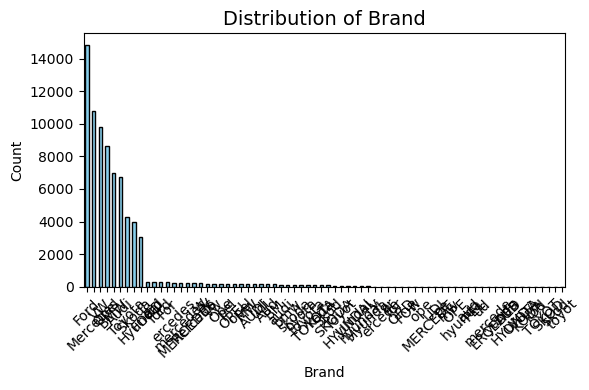

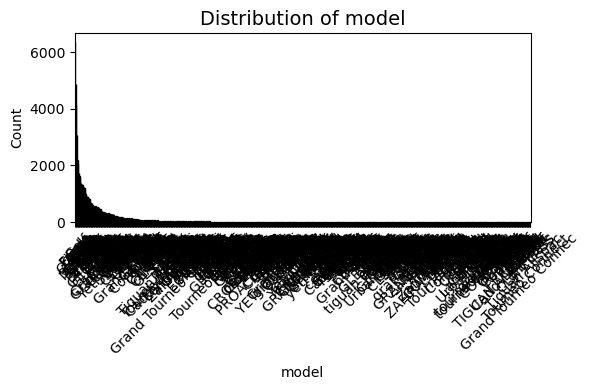

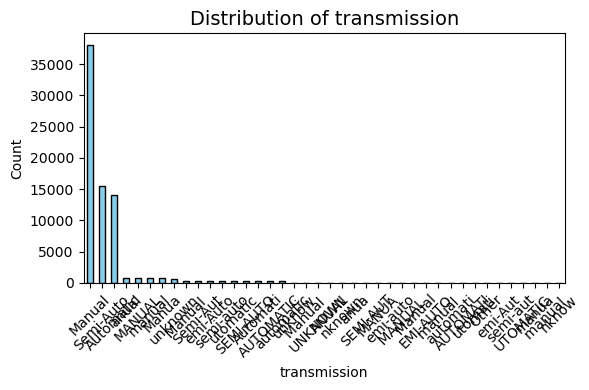

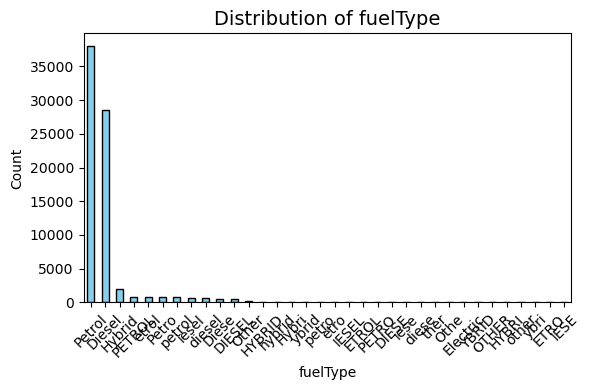

time: 3.28 s (started: 2025-12-16 16:50:55 +00:00)


In [40]:
for col in cat_vars:
    plt.figure(figsize=(6, 4))
    train[col].value_counts().plot(
        kind='bar', 
        color='skyblue', 
        edgecolor='black'
    )
    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)  # rotate labels if needed
    plt.tight_layout()
    plt.show()

*As suspected, the categorical variables contain wrongly written entries, that need to be corrected.*

In [41]:
train['Brand'].value_counts()

Brand
Ford        14806
Mercedes    10754
VW           9780
Opel         8645
BMW          6968
            ...  
kod             2
TOYOT           1
SKOD            1
skod            1
toyot           1
Name: count, Length: 72, dtype: int64

time: 6.71 ms (started: 2025-12-16 16:50:59 +00:00)


In [42]:
pd.set_option('display.max_rows', None)

time: 233 μs (started: 2025-12-16 16:50:59 +00:00)


In [43]:
train['Brand'].value_counts()

Brand
Ford        14806
Mercedes    10754
VW           9780
Opel         8645
BMW          6968
Audi         6749
Toyota       4289
Skoda        3973
Hyundai      3064
FORD          316
ord           315
ford          307
For           293
ercedes       233
mercedes      228
MERCEDES      227
Mercede       215
W             203
V             197
vw            193
Ope           180
pel           178
OPEL          169
opel          165
MW            145
AUDI          144
udi           143
Aud           142
BM            141
audi          135
bmw           134
skoda          93
oyota          91
toyota         84
TOYOTA         82
koda           80
Skod           79
SKODA          72
Toyot          72
HYUNDAI        72
yundai         68
hyundai        63
Hyunda         59
v               7
ercede          7
or              7
for             7
ORD             5
FOR             5
w               5
ope             4
MERCEDE         4
UDI             4
pe              4
mw              4
OPE 

time: 6.54 ms (started: 2025-12-16 16:50:59 +00:00)


In [44]:
brand_mapping = {
    **dict.fromkeys([
        'ford', 'f0rd', 'FORD', 'for', 'For', 'ord', 'ORD', 'or','FOR'
    ], 'Ford'),

    **dict.fromkeys([
        'mercedes', 'mercede', 'Mercede', 'mercedes-benz', 'MERCEDES',
        'ercede', 'MERCEDE', 'ERCEDES', 'ercedes', 'M'
    ], 'Mercedes'),

    **dict.fromkeys([
        'vw', 'v w', 'V', 'v', 'w', 'W'
    ], 'VW'),

    **dict.fromkeys([
        'audi', 'AUDI', 'udi', 'Aud', 'UDI', 'ud', 'aud', 'AUD'
    ], 'Audi'),

    **dict.fromkeys([
        'bmw', 'mw', 'BM', 'MW','bm'
    ], 'BMW'),

    **dict.fromkeys([
        'opel', 'Ope', 'pel', 'OPEL', 'pe', 'ope', 'OPE', 'PEL'
    ], 'Opel'),

    **dict.fromkeys([
        'toyota', 'oyota', 'TOYOTA', 'Toyot', 'toyot', 'OYOTA', 'TOYOT', 'oyot'
    ], 'Toyota'),

    **dict.fromkeys([
        'hyundai', 'HYUNDAI', 'yundai', 'Hyunda', 'hyunda', 'yunda', 'HYUNDA', 'YUNDAI'
    ], 'Hyundai'),

    **dict.fromkeys([
        'skoda', 'koda', 'SKODA', 'kod', 'KODA', 'SKOD', 'skod', 'Skod'
    ], 'Skoda'),
}

train['Brand'] = train['Brand'].replace(brand_mapping)

time: 145 ms (started: 2025-12-16 16:50:59 +00:00)


In [45]:
train['Brand'].value_counts()

Brand
Ford        16061
Mercedes    11674
VW          10385
Opel         9352
BMW          7392
Audi         7325
Toyota       4622
Skoda        4303
Hyundai      3334
Name: count, dtype: int64

time: 7.29 ms (started: 2025-12-16 16:50:59 +00:00)


In [46]:
train['model'].value_counts()

model
 Focus                    6351
 C Class                  4886
 Fiesta                   4130
 Golf                     3081
 Corsa                    2182
 Polo                     2046
 Astra                    1744
 A Class                  1618
 3 Series                 1566
 Kuga                     1382
 Mokka X                  1357
 Yaris                    1327
 Aygo                     1298
 1 Series                 1247
 A3                       1231
 E Class                  1196
 Tiguan                   1116
 Fabia                     990
 Octavia                   945
 Q3                        933
 A1                        889
 A4                        889
 Tucson                    843
 2 Series                  802
 EcoSport                  757
 I10                       683
 5 Series                  667
 Insignia                  660
 4 Series                  609
 GLC Class                 591
 Q5                        571
 Passat                    569
 A

time: 12 ms (started: 2025-12-16 16:50:59 +00:00)


In [47]:
train['model'] = (
    train['model']
    .astype(str)
    .str.lower()                        # lowercase everything
    .str.strip()                        # remove leading/trailing spaces
    .str.replace(r'[^a-z0-9 ]', '', regex=True)  # remove special chars except space
)

model_mapping = {
    **dict.fromkeys(['focus', 'focu'], 'Focus'),
    **dict.fromkeys(['c class', 'c clas', 'cclass'], 'C Class'),
    **dict.fromkeys(['fiesta', 'fiest'], 'Fiesta'),
    **dict.fromkeys(['golf', 'gol', 'golf sv', 'gol sv'], 'Golf'),
    **dict.fromkeys(['astra', 'astr'], 'Astra'),
    **dict.fromkeys(['1 series', '1 serie', '1series'], '1 Series'),
    **dict.fromkeys(['3 series', '3 serie', '3series'], '3 Series'),
    **dict.fromkeys(['tiguan', 'tiguan allspace', 'tigua'], 'Tiguan'),
    **dict.fromkeys(['yaris', 'yari'], 'Yaris'),
    **dict.fromkeys(['mokka', 'mokka x', 'mokaa', 'mokk'], 'Mokka'),
    **dict.fromkeys(['corsa', 'cors', 'c-hr', 'chr'], 'Corsa'),
    **dict.fromkeys(['t-roc', 'troc', 'tcros'], 'T-Roc'),
    **dict.fromkeys(['s-max', 'smax', 'sma'], 'S-MAX'),
    **dict.fromkeys(['c-max', 'cma', 'c-mas', 'c-maxi'], 'C-MAX'),
    **dict.fromkeys(['grand c-max', 'grand cma', 'grand c-mas'], 'Grand C-MAX'),
    **dict.fromkeys(['combo life', 'combo lif', 'combo'], 'Combo Life'),
    **dict.fromkeys(['b-max', 'bmax', 'b-ma'], 'B-MAX'),
    **dict.fromkeys(['glc class', 'glc clas', 'glc'], 'GLC Class'),
    **dict.fromkeys(['gle class', 'gle clas', 'gle'], 'GLE Class'),
    **dict.fromkeys(['sl class', 'sl clas'], 'SL Class'),
    **dict.fromkeys(['cla class', 'cla clas'], 'CLA Class'),
    **dict.fromkeys(['cl class', 'cl clas'], 'CL Class'),
    **dict.fromkeys(['e class', 'e clas'], 'E Class'),
    **dict.fromkeys(['a class', 'a clas'], 'A Class'),
    **dict.fromkeys(['2 series', '2 serie'], '2 Series'),
    **dict.fromkeys(['4 series', '4 serie'], '4 Series'),
    **dict.fromkeys(['5 series', '5 serie'], '5 Series'),
    **dict.fromkeys(['6 series', '6 serie'], '6 Series'),
    **dict.fromkeys(['7 series', '7 serie'], '7 Series'),
    **dict.fromkeys(['8 series', '8 serie'], '8 Series'),
}
train['model'] = train['model'].replace(model_mapping)

time: 213 ms (started: 2025-12-16 16:50:59 +00:00)


In [48]:
canonical_models = train['model'].value_counts().index.tolist()

train['model'] = train['model'].apply(fuzzy_match_model)

train['model'] = train['model'].str.title()

threshold = 5
model_counts = train['model'].value_counts()
rare_models = model_counts[model_counts <= threshold].index.tolist()
train['model'] = train['model'].replace(rare_models, 'Other')

time: 2.97 s (started: 2025-12-16 16:50:59 +00:00)


In [49]:
train['model'].value_counts()

model
Focus                    6913
C Class                  5288
Fiesta                   4470
Golf                     3510
Corsa                    2687
Polo                     2180
Mokka                    2017
Astra                    1915
A Class                  1735
3 Series                 1689
Nan                      1517
Kuga                     1472
Yaris                    1435
1 Series                 1358
Aygo                     1352
E Class                  1310
A3                       1285
Tiguan                   1277
Fabia                    1054
Octavia                  1000
Q3                        972
A4                        929
A1                        921
Tucson                    892
2 Series                  861
Ecosport                  808
5 Series                  727
I10                       716
Insignia                  710
Glc Class                 666
4 Series                  659
Passat                    611
Up                        596
Q5  

time: 10.3 ms (started: 2025-12-16 16:51:02 +00:00)


In [50]:
train['transmission'].value_counts()

transmission
Manual       38048
Semi-Auto    15545
Automatic    14001
anual          804
MANUAL         801
manual         770
Manua          759
unknown        690
 Manual        366
Semi-Aut       332
emi-Auto       325
semi-auto      324
utomatic       313
SEMI-AUTO      309
Automati       304
AUTOMATIC      289
automatic      282
unknow          18
Manual          16
UNKNOWN         14
ANUAL           13
nknown          13
anua            12
SEMI-AUT        11
MANUA           11
emi-auto        10
 MANUAL          9
 Manual          7
EMI-AUTO         7
 manual          6
automati         6
AUTOMATI         6
utomati          6
Other            5
emi-Aut          5
semi-aut         4
UTOMATIC         2
manua            2
manual           1
nknow            1
Name: count, dtype: int64

time: 5.6 ms (started: 2025-12-16 16:51:02 +00:00)


In [51]:
train['transmission'] = train['transmission'].str.strip().str.lower()

transmission_mapping = {
    **dict.fromkeys([
        'manual', 'MANUAL', 'Manua', 'Manual', ' Manual', 'MANUA', 
        'manua', 'anual', 'ANUAL', 'anua', ' MANUAL', ' manual', ' Manual', ' MANUAL', 'Manual ', 'manual ', 
        ' manual', ' Manual ', ' MANUAL ', ' manual '
    ], 'Manual'),

    **dict.fromkeys([
        'automatic', 'AUTOMATIC', 'Automati', 'utomatic', 'AUTOMATI', 
        'utomati', 'UTOMATIC', 'automati'
    ], 'Automatic'),

    **dict.fromkeys([
        'semi-auto', 'Semi-Auto', 'Semi-Aut', 'emi-Auto', 'emi-auto', 
        'SEMI-AUTO', 'SEMI-AUT', 'emi-Aut', 'semi-aut', 'EMI-AUTO','emi-aut'
    ], 'Semi-Auto'),

    **dict.fromkeys([
        'unknown', 'unknow', 'nknown', 'nknow', 'Other', 'UNKNOWN','other'
    ], 'Unknown')
}

train['transmission'] = train['transmission'].replace(transmission_mapping)
train['transmission'].value_counts()

transmission
Manual       41625
Semi-Auto    16872
Automatic    15209
Unknown        741
Name: count, dtype: int64

time: 115 ms (started: 2025-12-16 16:51:02 +00:00)


In [52]:
train['fuelType'].value_counts()

fuelType
Petrol      37992
Diesel      28474
Hybrid       2042
PETROL        795
etrol         794
Petro         785
petrol        746
iesel         603
diesel        599
Diese         582
DIESEL        582
Other         150
HYBRID         50
hybrid         46
Hybri          43
ybrid          37
petro          18
etro           17
IESEL          16
ETROL          16
PETRO          14
DIESE          10
iese           10
diese           8
ther            6
Othe            6
Electric        4
YBRID           3
OTHER           3
HYBRI           2
other           2
ybri            1
ETRO            1
IESE            1
Name: count, dtype: int64

time: 6.7 ms (started: 2025-12-16 16:51:02 +00:00)


In [53]:
train['fuelType'] = train['fuelType'].str.strip().str.lower()

fuel_mapping = {
    **dict.fromkeys([
        'petrol', 'Petrol', 'PETROL', 'etrol', 'Petro', 'petro', 'etro', 'ETROL', 'PETRO'
    ], 'Petrol'),

    **dict.fromkeys([
        'diesel', 'Diesel', 'DIESEL', 'iesel', 'Diese', 'IESEL', 'DIESE', 'iese', 'diese'
    ], 'Diesel'),

    **dict.fromkeys([
        'hybrid', 'Hybrid', 'HYBRID', 'Hybri', 'ybrid', 'YBRID', 'HYBRI', 'ybri','hybri'
    ], 'Hybrid'),

    **dict.fromkeys([
        'other', 'Other', 'OTHER', 'ther', 'Othe', 'Electric','electric','othe'
    ], 'Other')
}

train['fuelType'] = train['fuelType'].replace(fuel_mapping)

train['fuelType'].value_counts()

fuelType
Petrol    41178
Diesel    30885
Hybrid     2224
Other       171
Name: count, dtype: int64

time: 102 ms (started: 2025-12-16 16:51:02 +00:00)


In [54]:
brand_model_map = (
    train[train['Brand'].notna() & train['model'].notna()]
    .groupby('model')['Brand']
    .agg(lambda x: x.mode()[0] if len(x.mode()) > 0 else np.nan)
    .to_dict()
)

brand_model_map

{'1 Series': 'BMW',
 '2 Series': 'BMW',
 '3 Series': 'BMW',
 '4 Series': 'BMW',
 '5 Series': 'BMW',
 '6 Series': 'BMW',
 '7 Series': 'BMW',
 '8 Series': 'BMW',
 'A': 'Audi',
 'A Class': 'Mercedes',
 'A1': 'Audi',
 'A3': 'Audi',
 'A4': 'Audi',
 'A5': 'Audi',
 'A6': 'Audi',
 'A7': 'Audi',
 'A8': 'Audi',
 'Ada': 'Opel',
 'Adam': 'Opel',
 'Agila': 'Opel',
 'Amarok': 'VW',
 'Antara': 'Opel',
 'Arteon': 'VW',
 'Astra': 'Opel',
 'Auri': 'Toyota',
 'Auris': 'Toyota',
 'Avensis': 'Toyota',
 'Ayg': 'Toyota',
 'Aygo': 'Toyota',
 'B Clas': 'Mercedes',
 'B Class': 'Mercedes',
 'B-Max': 'Ford',
 'Beetle': 'VW',
 'Bma': 'Ford',
 'C Class': 'Mercedes',
 'Caddy Life': 'VW',
 'Caddy Maxi Life': 'VW',
 'California': 'VW',
 'Camry': 'Toyota',
 'Caravelle': 'VW',
 'Cc': 'VW',
 'Citig': 'Skoda',
 'Citigo': 'Skoda',
 'Cl Class': 'Mercedes',
 'Cla Class': 'Mercedes',
 'Clk': 'Mercedes',
 'Cls Class': 'Mercedes',
 'Cmax': 'Ford',
 'Combo Life': 'Opel',
 'Corolla': 'Toyota',
 'Corsa': 'Opel',
 'Crossland': 'Ope

time: 58.4 ms (started: 2025-12-16 16:51:02 +00:00)


In [55]:
train['Brand'] = train.apply(fill_brand_from_model, axis=1)

time: 533 ms (started: 2025-12-16 16:51:02 +00:00)


In [56]:
train['Brand'] = train['Brand'].fillna('Missing')
train['model'] = train['model'].fillna('Missing')
train['transmission'] = train['transmission'].fillna('Missing')
train['fuelType'] = train['fuelType'].fillna('Missing')

time: 14.5 ms (started: 2025-12-16 16:51:03 +00:00)


*The remaining missing values of the categorical variables will be considered as their own category - 'Missing'.*

### Numerical Variables

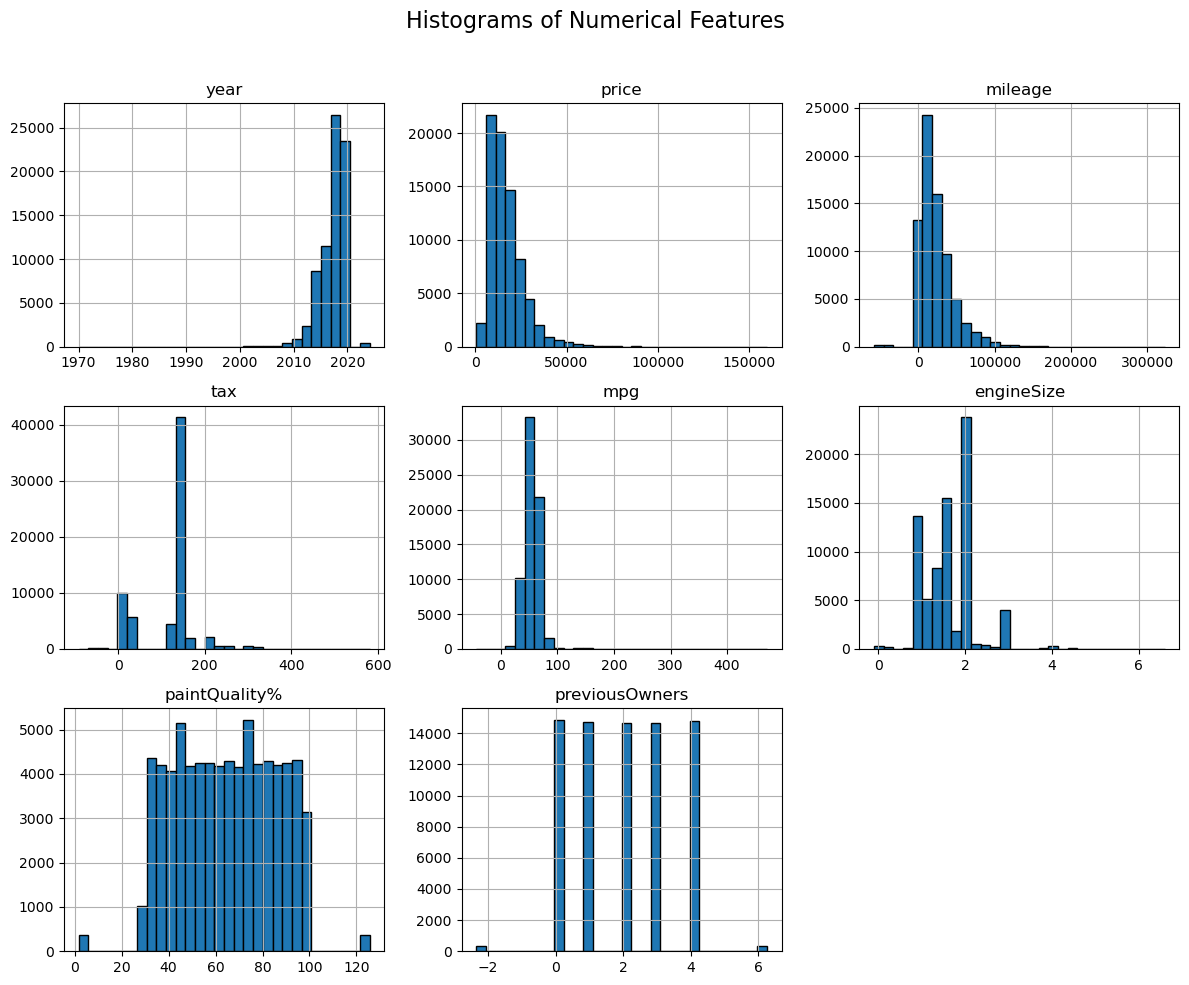

time: 798 ms (started: 2025-12-16 16:51:03 +00:00)


In [57]:
train[num_vars].hist(
    figsize=(12, 10), 
    bins=30, 
    edgecolor='black'
)

plt.suptitle('Histograms of Numerical Features', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # adjust for suptitle
plt.show()

In [58]:
train['year'].value_counts()

year
2019.000000    20270
2017.000000    16144
2016.000000    11502
2018.000000    10303
2015.000000     5733
2020.000000     3174
2014.000000     2930
2013.000000     1902
2012.000000      478
2011.000000      318
2010.000000      241
2009.000000      228
2008.000000      158
2007.000000      123
2010.676968       82
2023.116964       77
2005.000000       64
2006.000000       62
2010.746403       58
2023.977311       55
2023.389822       53
2011.210853       50
2010.565009       47
2023.267989       43
2023.605276       39
2009.816757       37
2010.371546       35
2004.000000       35
2024.121759       34
2003.000000       29
2023.367078       26
2002.000000       25
2012.695740       21
2010.268635       20
2022.696685       19
2001.000000       15
2011.111188       15
2022.878006       12
2000.000000        6
1998.000000        5
1999.000000        5
1970.000000        2
1997.000000        2
1996.000000        1
Name: count, dtype: int64

time: 2.85 ms (started: 2025-12-16 16:51:04 +00:00)


In [59]:
train['year'] = train['year'].apply(lambda x: int(x) if pd.notnull(x) else x)

time: 55.9 ms (started: 2025-12-16 16:51:04 +00:00)


In [60]:
train['year'].value_counts()

year
2019.0    20270
2017.0    16144
2016.0    11502
2018.0    10303
2015.0     5733
2020.0     3174
2014.0     2930
2013.0     1902
2012.0      499
2010.0      483
2011.0      383
2023.0      293
2009.0      265
2008.0      158
2007.0      123
2005.0       64
2006.0       62
2004.0       35
2024.0       34
2022.0       31
2003.0       29
2002.0       25
2001.0       15
2000.0        6
1998.0        5
1999.0        5
1970.0        2
1997.0        2
1996.0        1
Name: count, dtype: int64

time: 3.08 ms (started: 2025-12-16 16:51:04 +00:00)


In [61]:
train.loc[train['year'] > 2020, 'year'] = np.nan

time: 913 μs (started: 2025-12-16 16:51:04 +00:00)


In [62]:
train['mileage'].value_counts()

mileage
 1000.000000      577
 10.000000        560
 5000.000000      507
 6000.000000      340
 100.000000       318
 3000.000000      286
 2000.000000      260
 4000.000000      207
 2500.000000      153
 1500.000000      146
 25000.000000     128
 10000.000000     126
 50.000000        123
 3500.000000      121
 8000.000000      110
 20000.000000     107
 30000.000000     106
 123.000000       105
 15000.000000     104
 4500.000000      104
 7000.000000      101
 23000.000000      98
 22000.000000      98
 500.000000        97
 40000.000000      97
 26000.000000      96
 9000.000000       95
 45000.000000      91
 18000.000000      88
 27000.000000      86
 13000.000000      85
 14000.000000      84
 12000.000000      84
 82584.134420      82
 6500.000000       81
 33000.000000      81
 28000.000000      81
-42650.453719      78
 24000.000000      78
 101.000000        78
 35000.000000      76
 19000.000000      76
 21000.000000      75
 32000.000000      75
 11000.000000      74
 1

time: 369 ms (started: 2025-12-16 16:51:04 +00:00)


In [63]:
train.loc[train['mileage'] < 0, 'mileage'] = np.nan

time: 1.2 ms (started: 2025-12-16 16:51:04 +00:00)


In [64]:
train['mileage'].value_counts()

mileage
1000.000000      577
10.000000        560
5000.000000      507
6000.000000      340
100.000000       318
3000.000000      286
2000.000000      260
4000.000000      207
2500.000000      153
1500.000000      146
25000.000000     128
10000.000000     126
50.000000        123
3500.000000      121
8000.000000      110
20000.000000     107
30000.000000     106
123.000000       105
4500.000000      104
15000.000000     104
7000.000000      101
23000.000000      98
22000.000000      98
40000.000000      97
500.000000        97
26000.000000      96
9000.000000       95
45000.000000      91
18000.000000      88
27000.000000      86
13000.000000      85
12000.000000      84
14000.000000      84
82584.134420      82
6500.000000       81
28000.000000      81
33000.000000      81
24000.000000      78
101.000000        78
35000.000000      76
19000.000000      76
32000.000000      75
21000.000000      75
11000.000000      74
50000.000000      74
16000.000000      74
17000.000000      73
5.000

time: 370 ms (started: 2025-12-16 16:51:04 +00:00)


In [65]:
train['tax'].value_counts()

tax
 145.000000    32860
 150.000000     7400
 30.000000      5781
 20.000000      5610
 125.000000     4496
 0.000000       4320
 200.000000     1641
 160.000000     1401
 135.000000      846
 165.000000      468
 205.000000      466
 235.000000      458
 260.000000      371
 140.000000      256
 300.000000      235
 240.000000      135
 325.000000      123
 265.000000      107
 299.473504       77
-45.780610        76
 305.000000       63
 326.028233       62
 303.148891       59
-56.193202        56
 290.486785       55
-49.153541        54
-20.241079        53
 555.000000       48
 570.000000       42
-60.684095        40
 316.487189       35
 330.000000       35
 327.915778       34
-43.242082        33
-91.121630        25
 277.384254       23
-18.330743        23
 316.296306       21
-31.914945        18
 294.843409       15
 10.000000        15
 190.000000       13
 565.000000       13
 120.000000       12
 155.000000       11
 580.000000        9
 270.000000        8
 230.0000

time: 3.2 ms (started: 2025-12-16 16:51:05 +00:00)


In [66]:
train.loc[train['tax'] < 0, 'tax'] = np.nan

time: 1.13 ms (started: 2025-12-16 16:51:05 +00:00)


In [67]:
train['engineSize'].value_counts()

engineSize
 2.000000    20105
 1.000000    13613
 1.500000     9156
 1.400000     7432
 1.600000     6380
 1.200000     4749
 3.000000     3806
 2.100000     3624
 1.800000     1192
 1.300000      920
 1.700000      618
 1.100000      385
 2.500000      312
 4.000000      295
 2.200000      295
 2.300000      181
 0.000000      180
 2.900000      116
-0.103493       84
 2.631200       80
 0.307074       65
 3.723712       63
 2.985793       52
 0.186425       52
 0.739534       52
 2.064119       51
 4.400000       46
 2.400000       43
 0.154529       39
 5.000000       38
 3.739235       38
 0.313407       35
 5.500000       31
 3.822758       27
 2.800000       26
 2.619641       25
 0.162866       24
 1.900000       23
 0.191462       21
 4.200000       20
 2.781776       19
 6.200000       19
 3.200000       19
 0.371127       18
 4.700000       18
 5.200000       17
 2.663113       17
 3.500000       12
 2.700000        7
 0.600000        4
 5.400000        2
 4.100000        1
 

time: 2.7 ms (started: 2025-12-16 16:51:05 +00:00)


In [68]:
train.loc[train['engineSize'] <= 0, 'engineSize'] = np.nan

time: 736 μs (started: 2025-12-16 16:51:05 +00:00)


In [69]:
train['previousOwners'].value_counts()

previousOwners
 0.000000    14879
 4.000000    14760
 1.000000    14754
 3.000000    14648
 2.000000    14644
-2.340306       84
 6.258231       78
 6.245835       64
-2.345650       58
-2.339360       58
 6.258371       50
 6.233082       46
-2.299439       43
 6.230180       37
-2.335123       37
-2.312260       34
 6.248251       32
-2.337445       25
 6.217724       21
 6.241779       20
-2.340102       17
 6.227898       15
-2.317331       15
Name: count, dtype: int64

time: 2.48 ms (started: 2025-12-16 16:51:05 +00:00)


In [70]:
train.loc[train['previousOwners'] < 0, 'previousOwners'] = np.nan

time: 982 μs (started: 2025-12-16 16:51:05 +00:00)


In [71]:
train['previousOwners'] = train['previousOwners'].apply(lambda x: int(x) if pd.notnull(x) else x)

time: 54 ms (started: 2025-12-16 16:51:05 +00:00)


In [72]:
train['previousOwners'].value_counts()

previousOwners
0.0    14879
4.0    14760
1.0    14754
3.0    14648
2.0    14644
6.0      363
Name: count, dtype: int64

time: 2.58 ms (started: 2025-12-16 16:51:05 +00:00)


In [73]:
train['mpg'].value_counts()

mpg
 60.100000     4195
 65.700000     3188
 54.300000     2791
 64.200000     2459
 51.400000     2449
 55.400000     2358
 62.800000     2159
 47.900000     2154
 53.300000     2093
 58.900000     2044
 47.100000     2024
 56.500000     2017
 68.900000     1897
 57.700000     1751
 67.300000     1732
 52.300000     1724
 61.400000     1635
 74.300000     1528
 50.400000     1504
 43.500000     1478
 48.700000     1354
 49.600000     1294
 44.800000     1206
 39.200000     1106
 45.600000     1099
 44.100000      992
 72.400000      986
 42.200000      894
 46.300000      867
 41.500000      829
 57.600000      809
 39.800000      781
 40.900000      750
 70.600000      743
 42.800000      667
 78.500000      598
 38.200000      547
 69.000000      466
 37.700000      451
 40.400000      414
 37.200000      343
 34.000000      335
 76.300000      322
 32.800000      296
 36.700000      282
 36.200000      277
 61.700000      269
 34.900000      257
 38.700000      252
 35.300000      

time: 4.52 ms (started: 2025-12-16 16:51:05 +00:00)


In [74]:
train.loc[train['mpg'] <= 0, 'mpg'] = np.nan

time: 873 μs (started: 2025-12-16 16:51:05 +00:00)


##  Data Modification

*Clean, transform, and engineer features to prepare for modeling.*

###  Feature Engineering

*Create or transform variables to enhance model performance.*

In [75]:
train.drop(['paintQuality%'], axis = 1, inplace = True)

time: 4.78 ms (started: 2025-12-16 16:51:05 +00:00)


*The paintQuality% feature will not be needed, as it is filled by the mechanic during evaluation, and the model must be capable of
evaluating the price of a car based without needing the car to be taken to a mechanic.*

In [76]:
current_year = 2020
train['age'] = current_year - train['year']
min_age = train['age'].min()
max_age = train['age'].max()

print(f'Minimum age is {min_age} and maximum age is {max_age}.')

Minimum age is 0.0 and maximum age is 50.0.
time: 1.83 ms (started: 2025-12-16 16:51:05 +00:00)


In [77]:
train['age2'] = train['age']**2

time: 649 μs (started: 2025-12-16 16:51:05 +00:00)


In [78]:
train['log_mileage'] = np.where(
    train['mileage'].notna(),
    np.log1p(train['mileage']),  # log1p handles 0 safely
    np.nan
)

time: 1.5 ms (started: 2025-12-16 16:51:05 +00:00)


In [79]:
train['mileage_per_year'] = np.where(
    (train['age'].notna()) & (train['mileage'].notna()),
    np.where(
        train['age'] > 0,
        train['mileage'] / train['age'],   
        train['mileage']                   # If age == 0 → use mileage directly
    ),
    np.nan  # If age or mileage is missing
)


time: 1.59 ms (started: 2025-12-16 16:51:05 +00:00)


In [80]:
train['ownership_intensity'] = np.where(
    (train['age'].notna()) & (train['previousOwners'].notna()),
    np.where(
        train['age'] > 0,
        train['previousOwners'] / train['age'], 
        train['previousOwners']                  # if age == 0 → use raw owners count
    ),
    np.nan  # if age or previousOwners missing
)

time: 1.72 ms (started: 2025-12-16 16:51:05 +00:00)


In [81]:
train['efficiency_score'] = np.where(
    (train['engineSize'].notna()) & (train['engineSize'] != 0),
    train['mpg'] / train['engineSize'],
    np.nan  # undefined if engineSize missing or zero
)

time: 1.38 ms (started: 2025-12-16 16:51:05 +00:00)


In [82]:
train['tax_per_engine'] = np.where(
    (train['engineSize'].notna()) & (train['engineSize'] != 0),
    train['tax'] / train['engineSize'],
    np.nan  # undefined if engineSize missing or zero
)

time: 1.27 ms (started: 2025-12-16 16:51:05 +00:00)


In [83]:
train[['age','age2','log_mileage', 'mileage_per_year', 'ownership_intensity',
       'tax_per_engine', 'efficiency_score']].head()

,age,age2,log_mileage,mileage_per_year,ownership_intensity,tax_per_engine,efficiency_score
carID,,,,,,,
69512,4.0,16.0,10.254919,7105.25,1.0,NaN,5.708634
53000,1.0,1.0,8.431635,4589.00,1.0,96.666667,31.933333
6366,1.0,1.0,8.195610,3624.00,4.0,96.666667,27.266667
29021,2.0,4.0,9.116359,4551.00,NaN,145.000000,65.700000
10062,1.0,1.0,6.908755,1000.00,3.0,96.666667,28.533333


time: 7.09 ms (started: 2025-12-16 16:51:05 +00:00)


###  Data Preparation

*Handle outliers, missing values and scaling of data.*

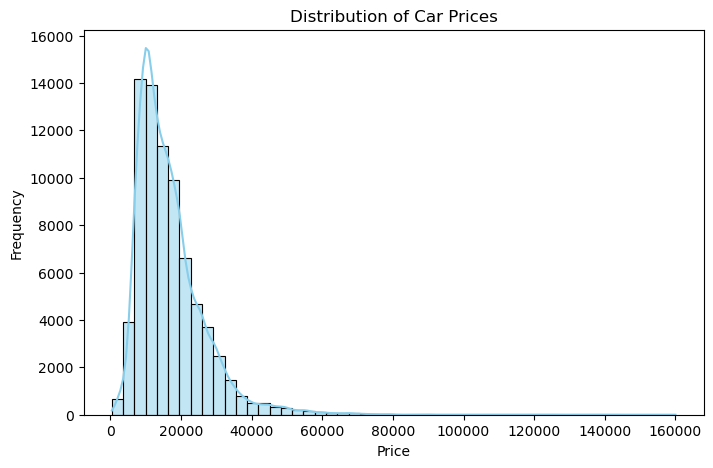

time: 396 ms (started: 2025-12-16 16:51:05 +00:00)


In [84]:
plt.figure(figsize=(8,5))
sns.histplot(train['price'], bins=50, kde=True, color='skyblue')
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [85]:
price_bins = [0, 10000, 20000, 30000, 40000, 60000, 80000, 100000, float('inf')]
price_labels = ['0-10k', '10-20k', '20-30k', '30-40k', '40-60k', '60-80k','80-100k', '100k+']

train['price_bin'] = pd.cut(train['price'], bins=price_bins, labels=price_labels)

print(train['price_bin'].value_counts().sort_index())

price_bin
0-10k      18686
10-20k     36979
20-30k     14201
30-40k      4029
40-60k      1750
60-80k       263
80-100k       29
100k+         32
Name: count, dtype: int64
time: 5.91 ms (started: 2025-12-16 16:51:05 +00:00)


In [86]:
X = train.drop(columns=['price', 'price_bin'], axis = 1)
y = train['price']

time: 5.42 ms (started: 2025-12-16 16:51:05 +00:00)


In [87]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=84,
    stratify=train['price_bin'],
    shuffle = True
)

time: 87.7 ms (started: 2025-12-16 16:51:05 +00:00)


*Due to the strong skewness of the target variable, we decided to create price bins and take that into consideration when doing split, to ensure that both training and validation sets have all bins represented (for example to not have the risk of all cars with a price above 40k to be on the validation set and none on the training one, making it impossible for the model to predict a price that was never seen.*

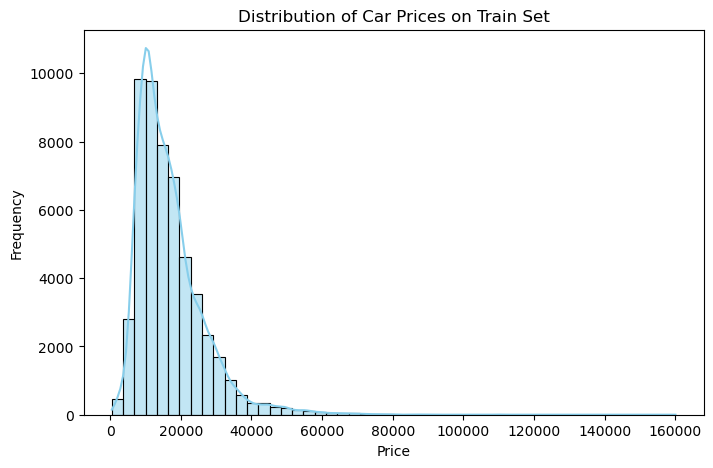

time: 247 ms (started: 2025-12-16 16:51:05 +00:00)


In [88]:
plt.figure(figsize=(8,5))
sns.histplot(y_train, bins=50, kde=True, color='skyblue')
plt.title("Distribution of Car Prices on Train Set")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

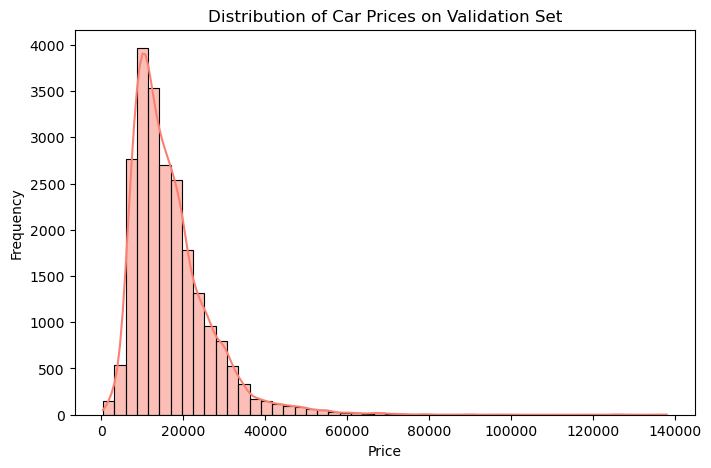

time: 186 ms (started: 2025-12-16 16:51:06 +00:00)


In [89]:
plt.figure(figsize=(8,5))
sns.histplot(y_val, bins=50, kde=True, color='salmon')
plt.title("Distribution of Car Prices on Validation Set")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

*The two figures demonstrate the effectivness of the stratification, as the distribution is the same for both datasets.*

In [90]:
X_train.head()

,Brand,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,previousOwners,age,age2,log_mileage,mileage_per_year,ownership_intensity,efficiency_score,tax_per_engine
carID,,,,,,,,,,,,,,,,,
62084,Opel,Zafira Tourer,2014.0,Manual,44930.0,Diesel,145.0,53.3,2.0,0.0,6.0,36.0,10.712883,7488.333333,0.000000,26.650000,72.5
55404,Toyota,Aygo,2015.0,Manual,41700.0,Petrol,0.0,69.0,1.0,0.0,5.0,25.0,10.638280,8340.000000,0.000000,69.000000,0.0
20728,Ford,Focus,2017.0,Manual,16447.0,Diesel,145.0,67.3,2.0,4.0,3.0,9.0,9.707959,5482.333333,1.333333,33.650000,72.5
29780,Ford,Other,2015.0,Manual,19502.0,Petrol,30.0,57.7,1.2,2.0,5.0,25.0,9.878324,3900.400000,0.400000,48.083333,25.0
3847,Audi,A3,2017.0,Manual,34000.0,Diesel,20.0,70.6,1.6,2.0,3.0,9.0,10.434145,11333.333333,0.666667,44.125000,12.5


time: 10.9 ms (started: 2025-12-16 16:51:06 +00:00)


In [91]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53178 entries, 62084 to 70885
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Brand                53178 non-null  object 
 1   model                53178 non-null  object 
 2   year                 51887 non-null  float64
 3   transmission         53178 non-null  object 
 4   mileage              51911 non-null  float64
 5   fuelType             53178 non-null  object 
 6   tax                  47362 non-null  float64
 7   mpg                  47595 non-null  float64
 8   engineSize           51932 non-null  float64
 9   previousOwners       51866 non-null  float64
 10  age                  51887 non-null  float64
 11  age2                 51887 non-null  float64
 12  log_mileage          51911 non-null  float64
 13  mileage_per_year     50646 non-null  float64
 14  ownership_intensity  50604 non-null  float64
 15  efficiency_score     46483 non-null  

Before encoding our categorical features, such as **Model**, we are only going to create a binary variable for luxury models of cars.

In [92]:
Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)
IQR = Q3 - Q1
upper_whisker = Q3 + 1.5 * IQR

print(f"Upper whisker threshold: £{upper_whisker:,.0f}")

Upper whisker threshold: £37,075
time: 2.79 ms (started: 2025-12-16 16:51:06 +00:00)


In [93]:
model_median_prices = train.loc[y_train.index].groupby('model')['price'].median()
expensive_models = model_median_prices[model_median_prices > upper_whisker].index.tolist()

print(f"Luxury models identified: {len(expensive_models)}\n")
print(expensive_models)

Luxury models identified: 23

['7 Series', '8 Series', 'California', 'Caravelle', 'G Class', 'Gle Class', 'Gls Class', 'I8', 'Land Cruiser', 'M2', 'M4', 'M5', 'Q7', 'Q8', 'R8', 'Rs4', 'Rs5', 'Rs6', 'S Class', 'Supra', 'X5', 'X6', 'X7']
time: 15.5 ms (started: 2025-12-16 16:51:06 +00:00)


In [94]:
X_train['is_luxury_model'] = X_train['model'].isin(expensive_models).astype(int)
X_val['is_luxury_model'] = X_val['model'].isin(expensive_models).astype(int)

print(f"Luxury model cars in train: {X_train['is_luxury_model'].sum()}\n")
print(f"Luxury model cars in val: {X_val['is_luxury_model'].sum()}\n")

Luxury model cars in train: 1198

Luxury model cars in val: 495

time: 7.25 ms (started: 2025-12-16 16:51:06 +00:00)


**_We will now perform Target Encoding and Frequency Encoding for the Categorical Features, so they are identified not only by the average price of the correspondent category, but also how frequent that category is._**

In [95]:
freq_brand = X_train['Brand'].value_counts(normalize=True)
X_train['Brand_Freq'] = X_train['Brand'].map(freq_brand)

target_brand = X_train.join(y_train).groupby('Brand')['price'].mean()
X_train['Brand_TE'] = X_train['Brand'].map(target_brand)

time: 24.1 ms (started: 2025-12-16 16:51:06 +00:00)


In [96]:
freq_transmission = X_train['transmission'].value_counts(normalize=True)
X_train['transmission_Freq'] = X_train['transmission'].map(freq_transmission)

target_transmission = X_train.join(y_train).groupby('transmission')['price'].mean()
X_train['transmission_TE'] = X_train['transmission'].map(target_transmission)

time: 22.3 ms (started: 2025-12-16 16:51:06 +00:00)


In [97]:
freq_fuel = X_train['fuelType'].value_counts(normalize=True)
X_train['fuelType_Freq'] = X_train['fuelType'].map(freq_fuel)

target_fuelType = X_train.join(y_train).groupby('fuelType')['price'].mean()
X_train['fuelType_TE'] = X_train['fuelType'].map(target_fuelType)

time: 17.1 ms (started: 2025-12-16 16:51:06 +00:00)


In [98]:
freq_model = X_train['model'].value_counts(normalize=True)
X_train['model_Freq'] = X_train['model'].map(freq_model)

target_model = X_train.join(y_train).groupby('model')['price'].mean()
X_train['model_TE'] = X_train['model'].map(target_model)

time: 25.2 ms (started: 2025-12-16 16:51:06 +00:00)


In [99]:
for col in cat_vars:
    unseen = set(X_val[col]) - set(X_train[col])
    print(f"{col}: {len(unseen)} unseen categories")
    if unseen:
        print(" →", unseen)

Brand: 0 unseen categories
model: 0 unseen categories
transmission: 0 unseen categories
fuelType: 0 unseen categories
time: 42 ms (started: 2025-12-16 16:51:06 +00:00)


In [100]:
X_val['Brand_Freq'] = X_val['Brand'].map(freq_brand)
X_val['Brand_TE'] = X_val['Brand'].map(target_brand)

X_val['transmission_Freq'] = X_val['transmission'].map(freq_transmission)
X_val['transmission_TE'] = X_val['transmission'].map(target_transmission)

X_val['fuelType_Freq'] = X_val['fuelType'].map(freq_fuel)
X_val['fuelType_TE'] = X_val['fuelType'].map(target_fuelType)

X_val['model_Freq'] = X_val['model'].map(freq_model)
X_val['model_TE'] = X_val['model'].map(target_model)

time: 13.1 ms (started: 2025-12-16 16:51:06 +00:00)


In [101]:
X_train['brand_model_interaction'] = X_train['Brand_TE'] * X_train['model_TE']
X_val['brand_model_interaction'] = X_val['Brand_TE'] * X_val['model_TE']

time: 1.17 ms (started: 2025-12-16 16:51:06 +00:00)


In [102]:
X_train['age_model_score'] = X_train['age'] * X_train['model_TE']
X_val['age_model_score'] = X_val['age'] * X_val['model_TE']

time: 1.35 ms (started: 2025-12-16 16:51:06 +00:00)


In [103]:
X_train.drop(['Brand', 'transmission', 'fuelType', 'model'], axis = 1, inplace = True)
X_val.drop(['Brand', 'transmission', 'fuelType', 'model'], axis = 1, inplace = True)

time: 8.16 ms (started: 2025-12-16 16:51:06 +00:00)


In [104]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53178 entries, 62084 to 70885
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     51887 non-null  float64
 1   mileage                  51911 non-null  float64
 2   tax                      47362 non-null  float64
 3   mpg                      47595 non-null  float64
 4   engineSize               51932 non-null  float64
 5   previousOwners           51866 non-null  float64
 6   age                      51887 non-null  float64
 7   age2                     51887 non-null  float64
 8   log_mileage              51911 non-null  float64
 9   mileage_per_year         50646 non-null  float64
 10  ownership_intensity      50604 non-null  float64
 11  efficiency_score         46483 non-null  float64
 12  tax_per_engine           46260 non-null  float64
 13  is_luxury_model          53178 non-null  int64  
 14  Brand_Freq             

In [105]:
X_val.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22791 entries, 3950 to 42585
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     22233 non-null  float64
 1   mileage                  22227 non-null  float64
 2   tax                      20327 non-null  float64
 3   mpg                      20414 non-null  float64
 4   engineSize               22257 non-null  float64
 5   previousOwners           22182 non-null  float64
 6   age                      22233 non-null  float64
 7   age2                     22233 non-null  float64
 8   log_mileage              22227 non-null  float64
 9   mileage_per_year         21679 non-null  float64
 10  ownership_intensity      21642 non-null  float64
 11  efficiency_score         19925 non-null  float64
 12  tax_per_engine           19841 non-null  float64
 13  is_luxury_model          22791 non-null  int64  
 14  Brand_Freq              

In [106]:
num_vars = X_train.select_dtypes(include=np.number).columns.tolist()

print(num_vars)

['year', 'mileage', 'tax', 'mpg', 'engineSize', 'previousOwners', 'age', 'age2', 'log_mileage', 'mileage_per_year', 'ownership_intensity', 'efficiency_score', 'tax_per_engine', 'is_luxury_model', 'Brand_Freq', 'Brand_TE', 'transmission_Freq', 'transmission_TE', 'fuelType_Freq', 'fuelType_TE', 'model_Freq', 'model_TE', 'brand_model_interaction', 'age_model_score']
time: 4.75 ms (started: 2025-12-16 16:51:06 +00:00)


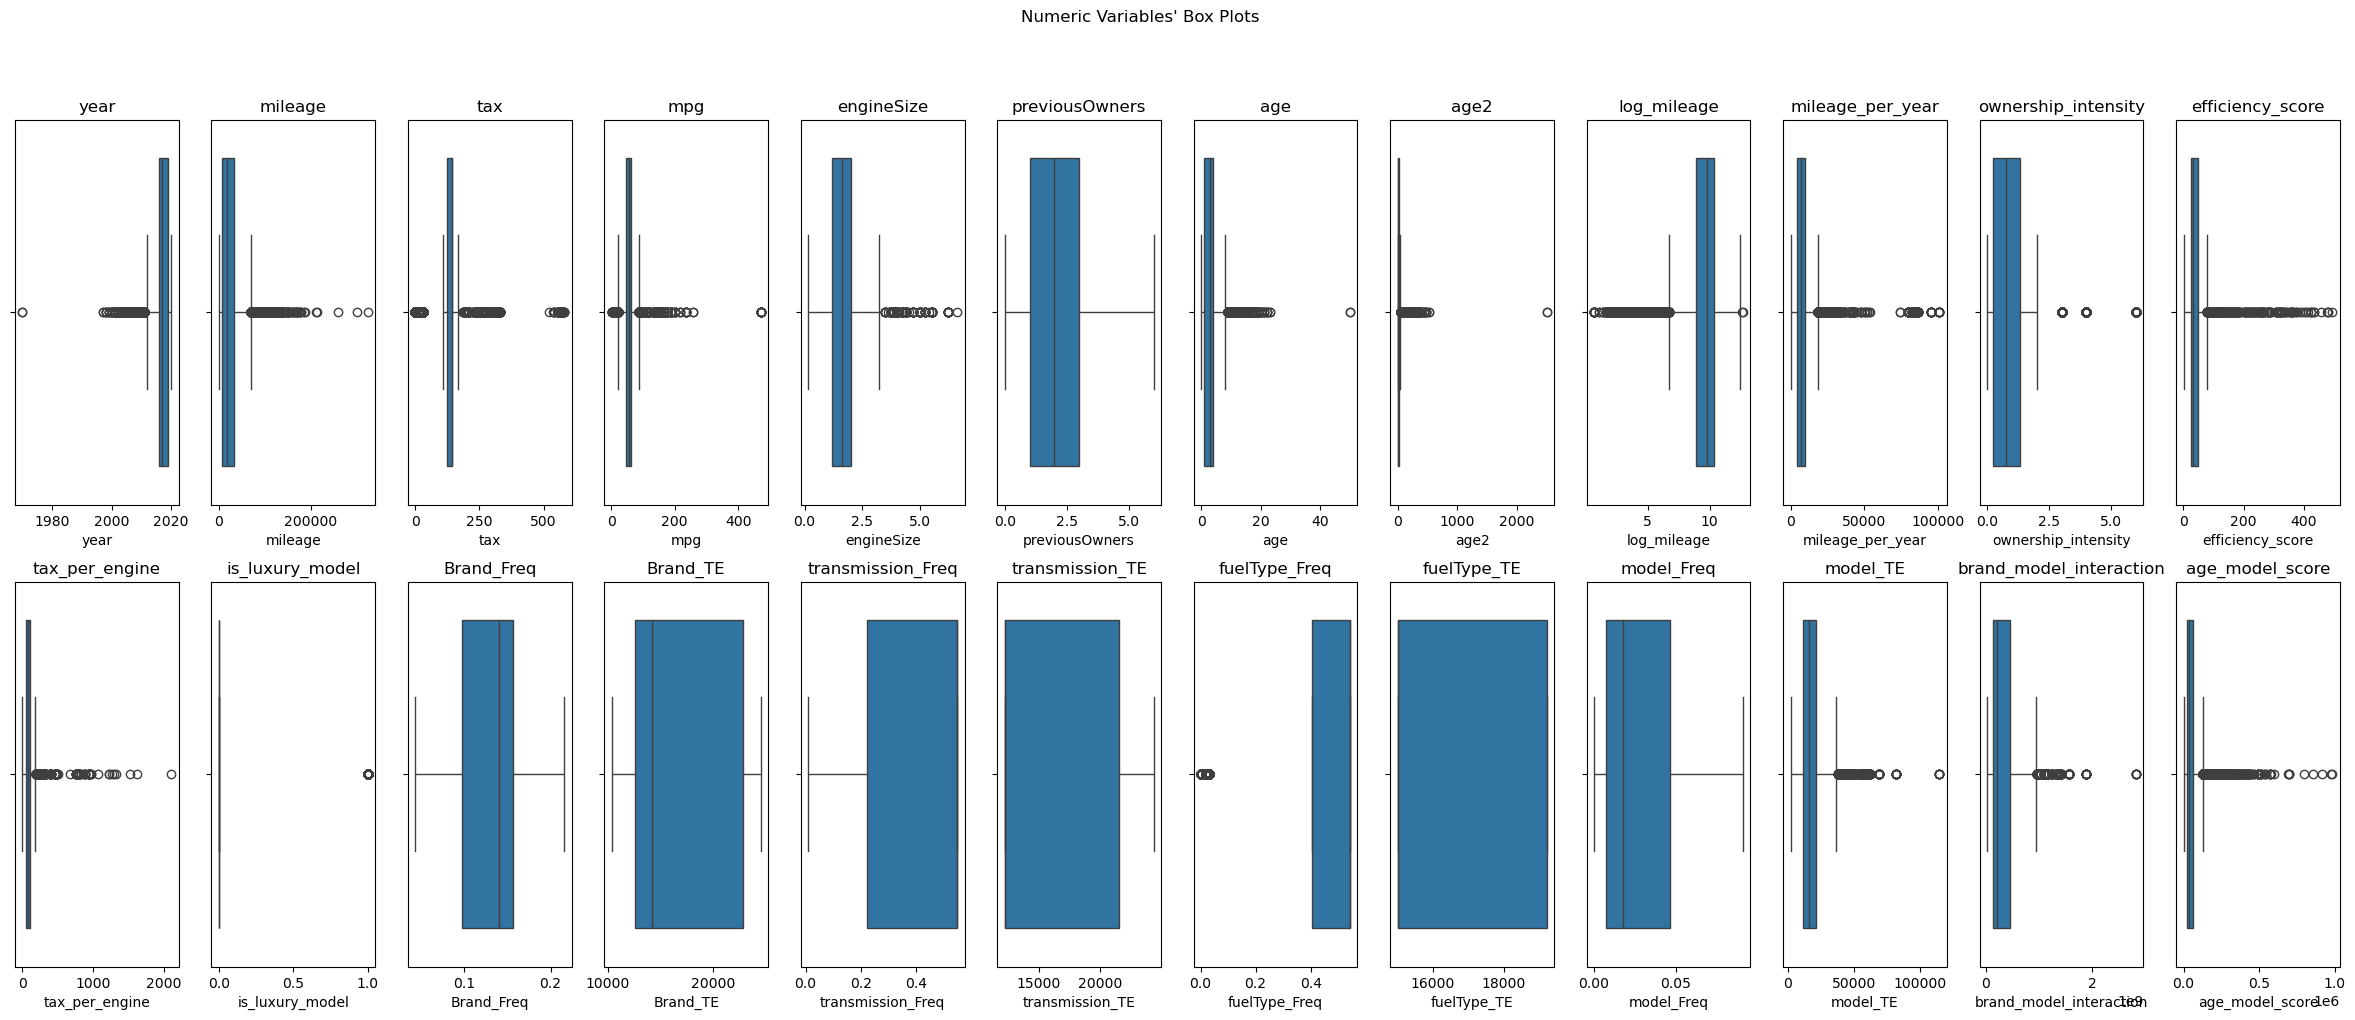

time: 2.44 s (started: 2025-12-16 16:51:06 +00:00)


In [107]:
plot_multiple_boxplots(X_train, num_vars)

In [108]:
outlier_summary = outlier_percentage_iqr(X_train, num_vars)
(outlier_summary.style
    .background_gradient(subset=['% Lower Outliers'], cmap='Blues')   
    .background_gradient(subset=['% Upper Outliers'], cmap='Reds')   
    .background_gradient(subset=['% Total Outliers'], cmap='Purples') 
    .format({
        '% Lower Outliers': '{:.2f}',
        '% Upper Outliers': '{:.2f}',
        '% Total Outliers': '{:.2f}'
    }))

,Variable,% Lower Outliers,% Upper Outliers,% Total Outliers
0,tax,23.24,6.18,29.42
1,ownership_intensity,0.00,12.75,12.75
2,age2,0.00,5.52,5.52
3,fuelType_Freq,5.16,0.00,5.16
4,mileage,0.00,4.39,4.39
5,age_model_score,0.00,4.37,4.37
6,log_mileage,4.29,0.00,4.30
7,mileage_per_year,0.00,2.66,2.66
8,is_luxury_model,0.00,2.25,2.25
9,year,2.24,0.00,2.24


time: 117 ms (started: 2025-12-16 16:51:08 +00:00)


In [109]:
X_train.skew().sort_values()

fuelType_Freq              -2.264703
log_mileage                -2.241431
year                       -2.168655
transmission_Freq          -0.329511
previousOwners              0.069868
tax                         0.080981
Brand_Freq                  0.125285
fuelType_TE                 0.215849
Brand_TE                    0.344173
transmission_TE             0.356713
model_Freq                  1.101065
engineSize                  1.325751
ownership_intensity         1.398558
brand_model_interaction     1.470335
mileage                     1.816524
model_TE                    1.911898
age                         2.168655
age_model_score             3.667419
mileage_per_year            5.060595
tax_per_engine              6.043326
is_luxury_model             6.435399
efficiency_score            6.532664
mpg                         6.908939
age2                       29.434910
dtype: float64

time: 7.82 ms (started: 2025-12-16 16:51:09 +00:00)


In [110]:
left_skewed = ['year', 'log_mileage']
right_skewed = ['engineSize', 'ownership_intensity', 'mileage', 
                'age', 'mileage_per_year', 'tax_per_engine', 'mpg', 'efficiency_score','age2']

time: 283 μs (started: 2025-12-16 16:51:09 +00:00)


<hr>

**_As we are keeping outliers on many of our variables we will be using Robust Scaler since it handles outliers better than other scaling methods._**

In [111]:
scaler = RobustScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)

time: 38.8 ms (started: 2025-12-16 16:51:09 +00:00)


In [112]:
X_train = pd.DataFrame(X_train_scaled, columns = X_train.columns).set_index(X_train.index)
X_train.head()

,year,mileage,tax,mpg,engineSize,previousOwners,age,age2,log_mileage,mileage_per_year,...,Brand_Freq,Brand_TE,transmission_Freq,transmission_TE,fuelType_Freq,fuelType_TE,model_Freq,model_TE,brand_model_interaction,age_model_score
carID,,,,,,,,,,,,,,,,,,,,,
62084,-1.000000,1.105710,0.00,-0.060606,0.50,-1.0,1.000000,1.800000,0.651780,0.117424,...,-0.223363,-0.371145,0.0,0.0,-1.0,1.0,-0.442465,-0.584384,-0.321240,0.592227
55404,-0.666667,0.976155,-7.25,0.890909,-0.75,-1.0,0.666667,1.066667,0.600635,0.266445,...,-1.334403,-0.163729,0.0,0.0,0.0,0.0,-0.009148,-0.801480,-0.338561,0.107677
20728,0.000000,-0.036741,0.00,0.787879,0.50,1.0,0.000000,0.000000,-0.037154,-0.233579,...,1.286585,-0.151287,0.0,0.0,-1.0,1.0,1.870968,-0.255379,-0.126064,0.119181
29780,-0.666667,0.085795,-5.75,0.206061,-0.50,0.0,0.666667,1.066667,0.079641,-0.510379,...,1.286585,-0.151287,0.0,0.0,0.0,0.0,-0.392393,0.073889,0.000210,1.119107
3847,0.000000,0.667308,-6.25,0.987879,0.00,0.0,0.000000,0.000000,0.460689,0.790207,...,-0.721759,0.848713,0.0,0.0,-1.0,1.0,-0.035147,0.185816,0.595993,0.425043


time: 12.5 ms (started: 2025-12-16 16:51:09 +00:00)


In [113]:
X_val_scaled = scaler.transform(X_val)
X_val = pd.DataFrame(X_val_scaled, columns = X_val.columns).set_index(X_val.index)
X_val.head()

,year,mileage,tax,mpg,engineSize,previousOwners,age,age2,log_mileage,mileage_per_year,...,Brand_Freq,Brand_TE,transmission_Freq,transmission_TE,fuelType_Freq,fuelType_TE,model_Freq,model_TE,brand_model_interaction,age_model_score
carID,,,,,,,,,,,,,,,,,,,,,
3950,-0.666667,0.632894,-6.25,0.351515,NaN,-1.0,0.666667,1.066667,0.443167,-0.033044,...,-0.721759,0.848713,-1.000000,1.303876,0.0,0.0,-0.035147,0.185816,0.595993,1.248430
57339,0.000000,0.080741,0.75,-0.654545,-0.250,1.0,0.000000,0.000000,0.075197,-0.062744,...,-0.223363,-0.371145,-1.062292,1.000000,0.0,0.0,0.233510,-0.440341,-0.275827,-0.009046
74138,-1.000000,1.306781,-6.25,0.066667,0.500,1.0,1.000000,1.800000,0.724294,0.263616,...,0.000000,0.255459,-1.646592,0.465855,-1.0,1.0,-0.402022,-0.245945,0.047929,1.061480
61415,0.000000,0.976837,0.00,0.133333,NaN,-0.5,0.000000,0.000000,0.600915,1.240304,...,-0.223363,-0.371145,-1.000000,1.303876,-1.0,1.0,0.233510,-0.440341,-0.275827,-0.009046
71835,1.000000,-0.696228,0.00,-0.733333,-0.125,1.0,-1.000000,-0.600000,-5.464168,-1.191982,...,0.000000,0.255459,0.000000,0.000000,0.0,0.0,-0.288878,0.674377,0.517039,-0.810037


time: 15.6 ms (started: 2025-12-16 16:51:09 +00:00)


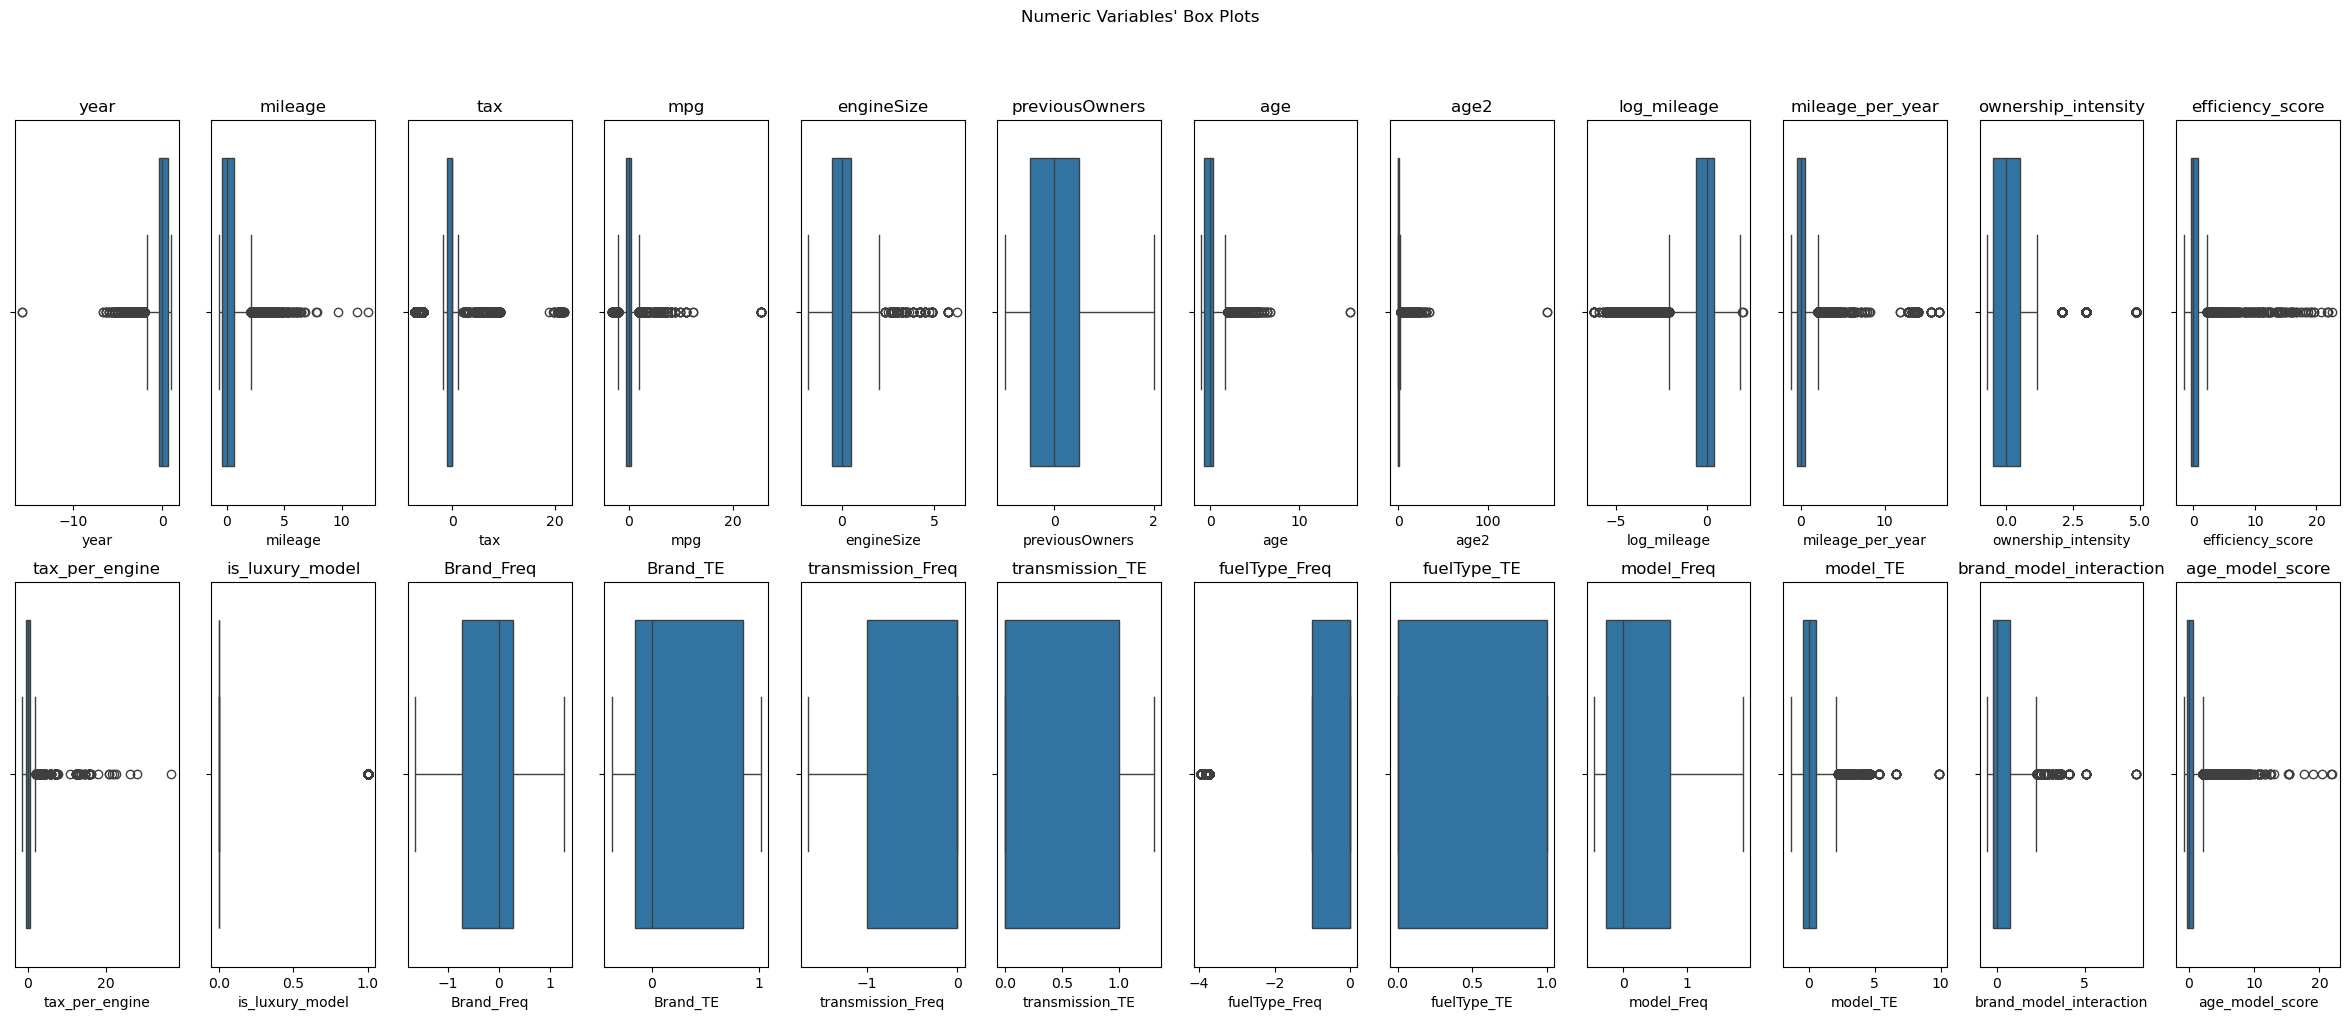

time: 2.37 s (started: 2025-12-16 16:51:09 +00:00)


In [114]:
plot_multiple_boxplots(X_train, num_vars)

In [115]:
num_vars.remove('is_luxury_model')

time: 198 μs (started: 2025-12-16 16:51:11 +00:00)


In [116]:
num_vars

['year',
 'mileage',
 'tax',
 'mpg',
 'engineSize',
 'previousOwners',
 'age',
 'age2',
 'log_mileage',
 'mileage_per_year',
 'ownership_intensity',
 'efficiency_score',
 'tax_per_engine',
 'Brand_Freq',
 'Brand_TE',
 'transmission_Freq',
 'transmission_TE',
 'fuelType_Freq',
 'fuelType_TE',
 'model_Freq',
 'model_TE',
 'brand_model_interaction',
 'age_model_score']

time: 1.09 ms (started: 2025-12-16 16:51:11 +00:00)


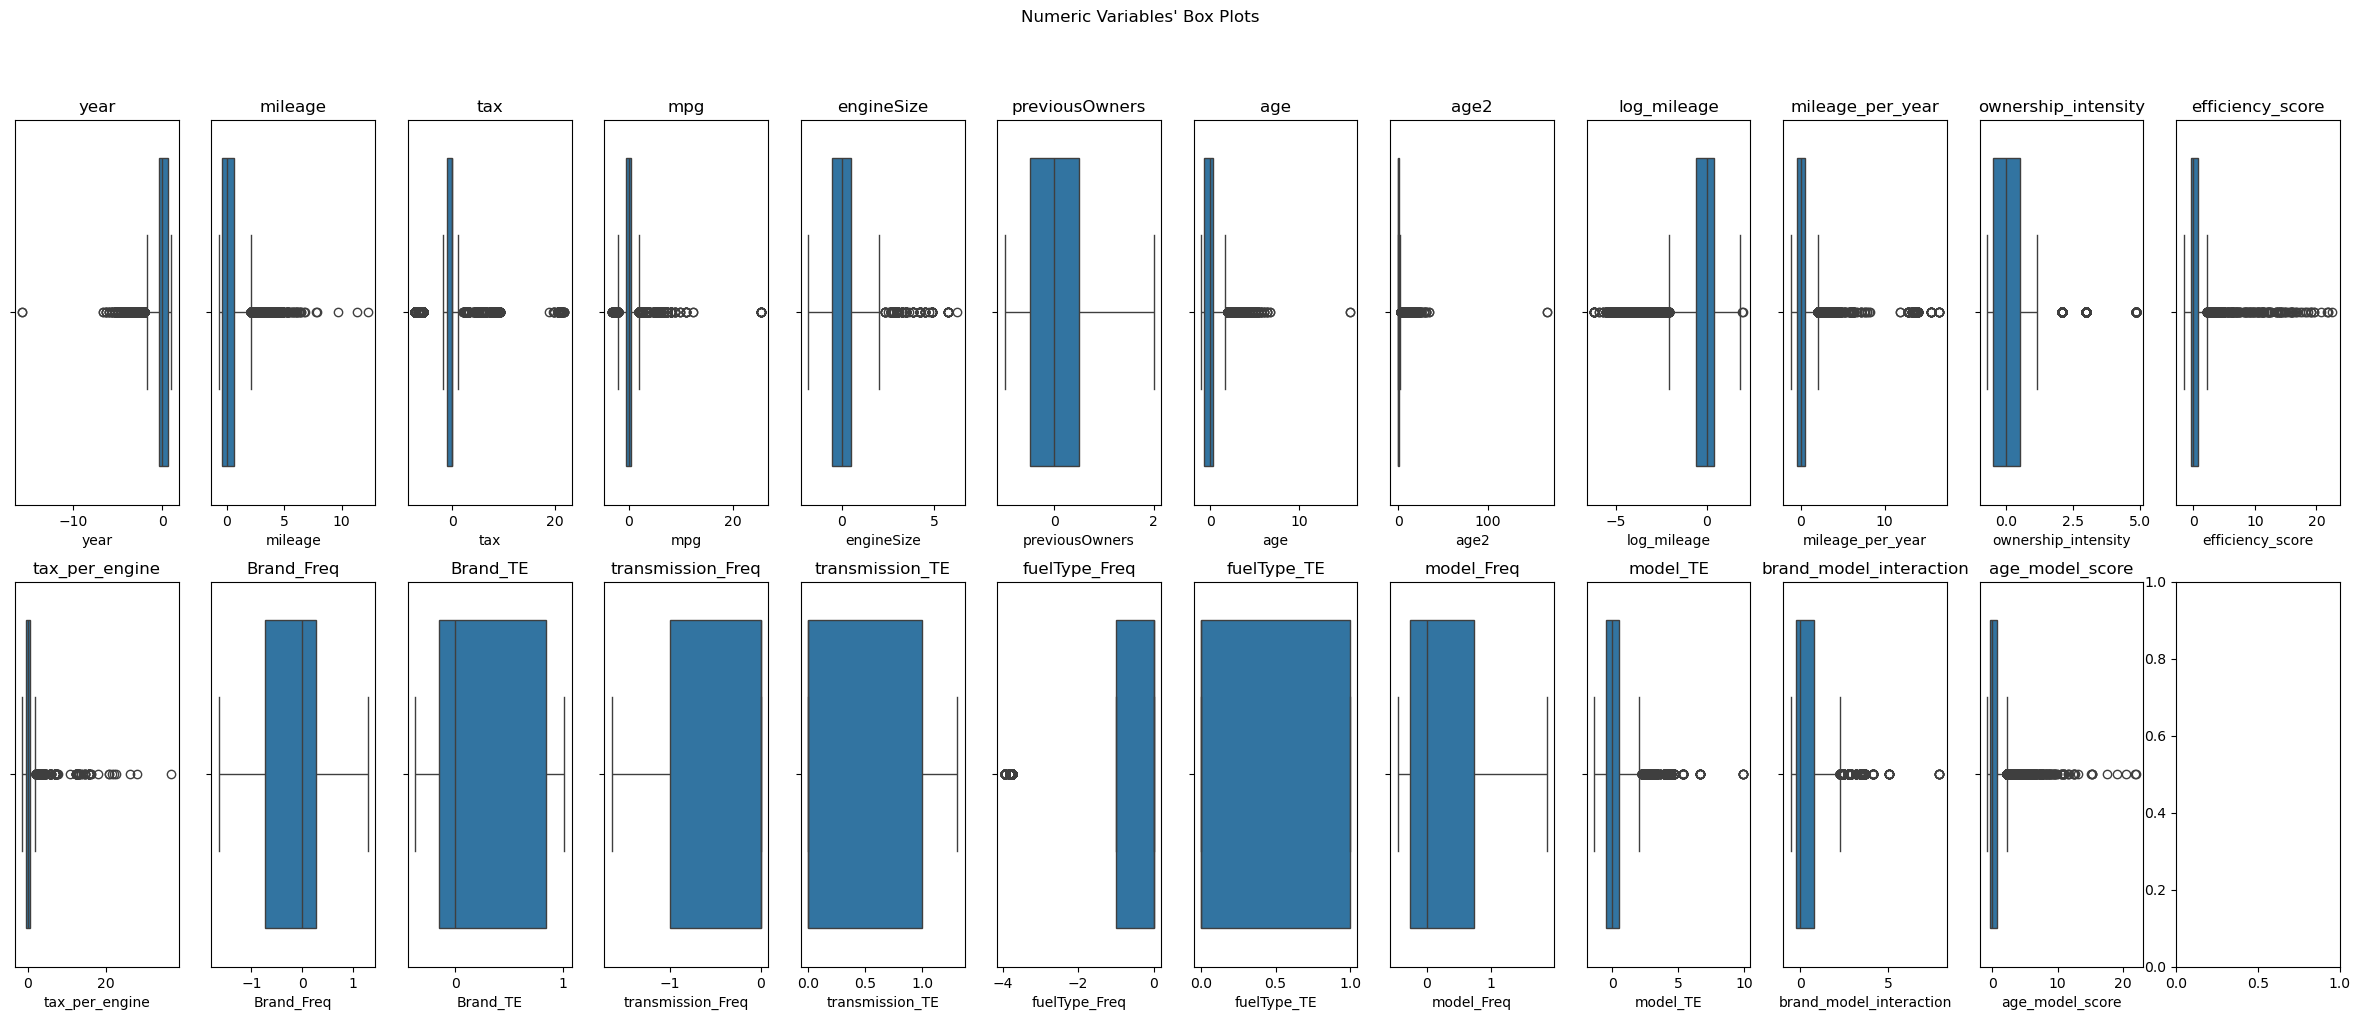

time: 2.36 s (started: 2025-12-16 16:51:11 +00:00)


In [117]:
plot_multiple_boxplots(X_train, num_vars)

In [118]:
missing_summary = pd.DataFrame({
    'Missing Count': X_train.isna().sum(),
    'Missing %': (X_train.isna().mean() * 100).round(2)
})
missing_summary = missing_summary.sort_values(by='Missing %', ascending=False)
missing_summary.style.background_gradient(subset=['Missing %'], cmap='Reds')

,Missing Count,Missing %
tax_per_engine,6918,13.010000
efficiency_score,6695,12.590000
tax,5816,10.940000
mpg,5583,10.500000
ownership_intensity,2574,4.840000
mileage_per_year,2532,4.760000
previousOwners,1312,2.470000
year,1291,2.430000
age2,1291,2.430000
age,1291,2.430000


time: 8.28 ms (started: 2025-12-16 16:51:13 +00:00)


*For the missing values of the numerical features, we will use the iterative imputer, given the fact it uses the relationships between features to predict the missing records.*

In [119]:
all_impute_vars = ['tax_per_engine', 'efficiency_score', 'tax', 'mpg', 'ownership_intensity',
                   'mileage_per_year', 'previousOwners', 'year',  'age', 'log_mileage', 'mileage', 'engineSize','age_model_score','age2']

te_vars = ['transmission_TE', 'Brand_TE', 'fuelType_TE', 'model_TE','brand_model_interaction']

Freq_vars = ['transmission_Freq', 'Brand_Freq', 'fuelType_Freq', 'model_Freq']

time: 386 μs (started: 2025-12-16 16:51:13 +00:00)


In [120]:
imputer = IterativeImputer(random_state=84, max_iter=30, verbose= 2)
X_train[all_impute_vars] = imputer.fit_transform(X_train[all_impute_vars])

[IterativeImputer] Completing matrix with shape (53178, 14)
[IterativeImputer] Ending imputation round 1/30, elapsed time 1.18
[IterativeImputer] Change: 28.68300895878313, scaled tolerance: 0.16606666666666667 
[IterativeImputer] Ending imputation round 2/30, elapsed time 2.45
[IterativeImputer] Change: 9.993337428078547, scaled tolerance: 0.16606666666666667 
[IterativeImputer] Ending imputation round 3/30, elapsed time 3.67
[IterativeImputer] Change: 6.552192033839086, scaled tolerance: 0.16606666666666667 
[IterativeImputer] Ending imputation round 4/30, elapsed time 4.96
[IterativeImputer] Change: 4.340964141243932, scaled tolerance: 0.16606666666666667 
[IterativeImputer] Ending imputation round 5/30, elapsed time 6.31
[IterativeImputer] Change: 2.89022912983338, scaled tolerance: 0.16606666666666667 
[IterativeImputer] Ending imputation round 6/30, elapsed time 7.60
[IterativeImputer] Change: 1.933465979224641, scaled tolerance: 0.16606666666666667 
[IterativeImputer] Ending imp

In [121]:
missing_summary_after = pd.DataFrame({
    'Missing Count': X_train.isna().sum(),
    'Missing %': (X_train.isna().mean() * 100).round(2)
})
missing_summary_after = missing_summary_after.sort_values(by='Missing %', ascending=False)
missing_summary_after.style.background_gradient(subset=['Missing %'], cmap='Greens')

,Missing Count,Missing %
year,0,0.000000
mileage,0,0.000000
brand_model_interaction,0,0.000000
model_TE,0,0.000000
model_Freq,0,0.000000
fuelType_TE,0,0.000000
fuelType_Freq,0,0.000000
transmission_TE,0,0.000000
transmission_Freq,0,0.000000
Brand_TE,0,0.000000


time: 10 ms (started: 2025-12-16 16:51:29 +00:00)


In [122]:
X_val[all_impute_vars] = imputer.transform(X_val[all_impute_vars])

[IterativeImputer] Completing matrix with shape (22791, 14)
[IterativeImputer] Ending imputation round 1/13, elapsed time 0.01
[IterativeImputer] Ending imputation round 2/13, elapsed time 0.01
[IterativeImputer] Ending imputation round 3/13, elapsed time 0.02
[IterativeImputer] Ending imputation round 4/13, elapsed time 0.02
[IterativeImputer] Ending imputation round 5/13, elapsed time 0.02
[IterativeImputer] Ending imputation round 6/13, elapsed time 0.03
[IterativeImputer] Ending imputation round 7/13, elapsed time 0.03
[IterativeImputer] Ending imputation round 8/13, elapsed time 0.04
[IterativeImputer] Ending imputation round 9/13, elapsed time 0.04
[IterativeImputer] Ending imputation round 10/13, elapsed time 0.05
[IterativeImputer] Ending imputation round 11/13, elapsed time 0.05
[IterativeImputer] Ending imputation round 12/13, elapsed time 0.06
[IterativeImputer] Ending imputation round 13/13, elapsed time 0.06
time: 70.9 ms (started: 2025-12-16 16:51:29 +00:00)


In [123]:
X_val.isna().sum()

year                       0
mileage                    0
tax                        0
mpg                        0
engineSize                 0
previousOwners             0
age                        0
age2                       0
log_mileage                0
mileage_per_year           0
ownership_intensity        0
efficiency_score           0
tax_per_engine             0
is_luxury_model            0
Brand_Freq                 0
Brand_TE                   0
transmission_Freq          0
transmission_TE            0
fuelType_Freq              0
fuelType_TE                0
model_Freq                 0
model_TE                   0
brand_model_interaction    0
age_model_score            0
dtype: int64

time: 2.96 ms (started: 2025-12-16 16:51:29 +00:00)


### Feature Selection

*Checking which variables are redundant or irrelevant for prediction.*

In [124]:
df_corr = pd.concat([X_train, y_train], axis=1)

time: 6.4 ms (started: 2025-12-16 16:51:29 +00:00)


In [125]:
cor_spearman = df_corr.corr(method ='spearman')

time: 112 ms (started: 2025-12-16 16:51:29 +00:00)


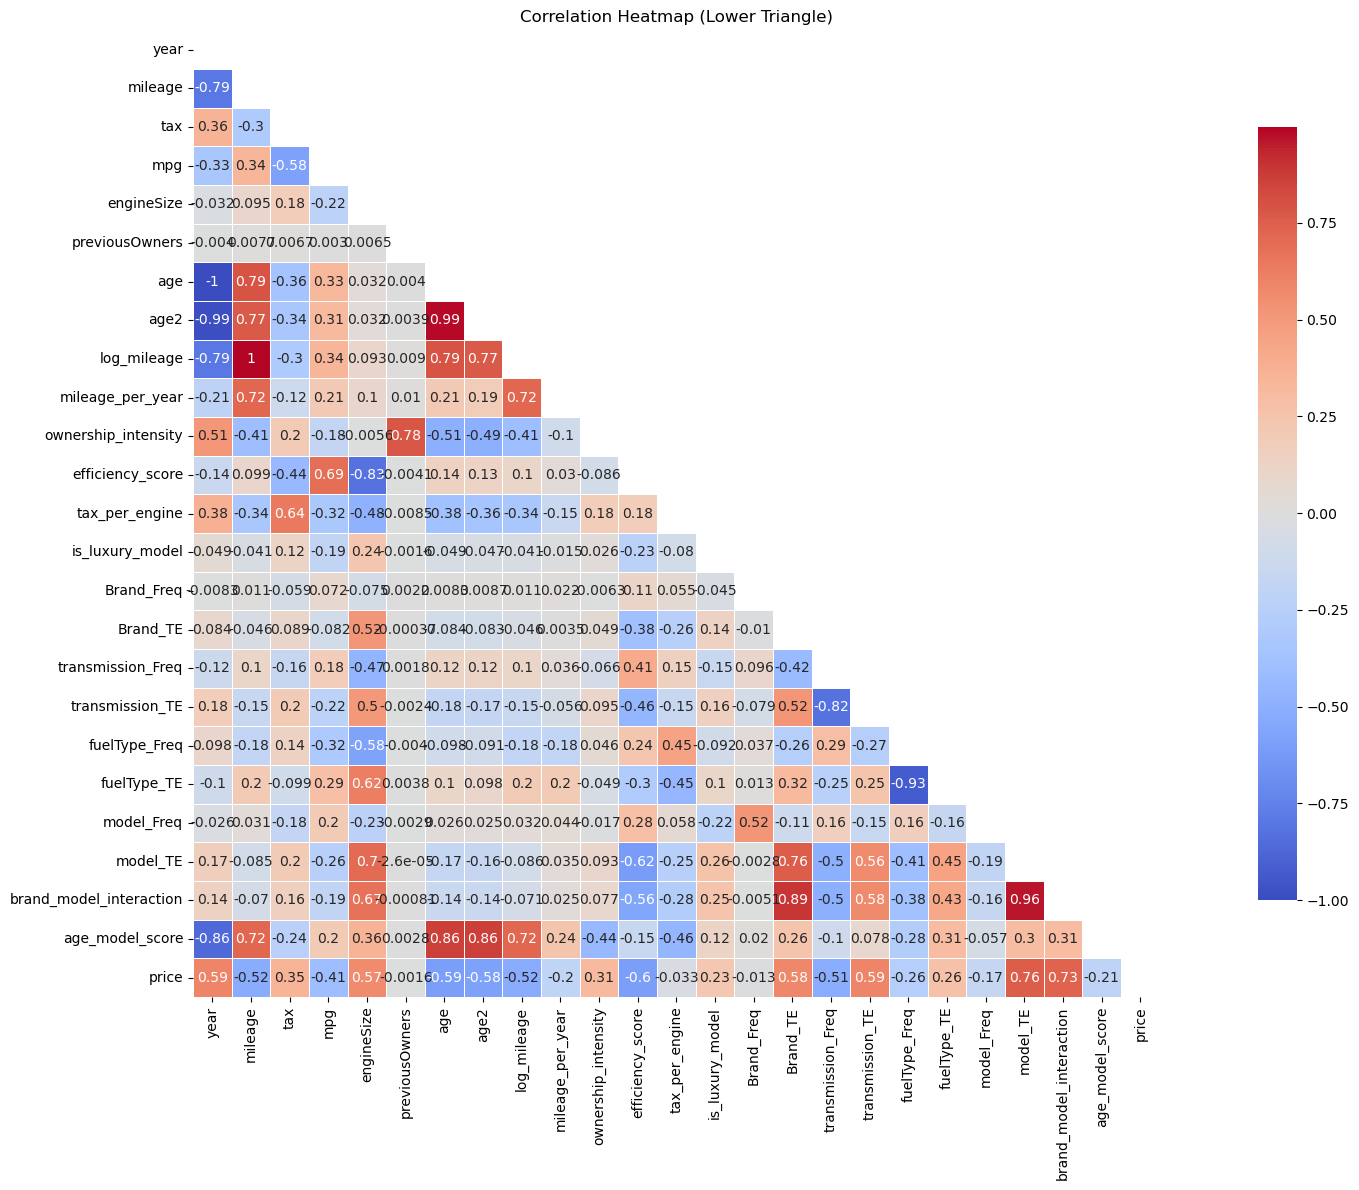

time: 584 ms (started: 2025-12-16 16:51:29 +00:00)


In [126]:
mask = np.triu(np.ones_like(cor_spearman, dtype=bool))

# Create heatmap
plt.figure(figsize=(20, 12))
sns.heatmap(cor_spearman, 
            mask=mask,           
            annot=True,          
            cmap='coolwarm',    
            center=0,            
            square=True,         
            linewidths=0.5,      
            cbar_kws={"shrink": 0.8})

plt.title('Correlation Heatmap (Lower Triangle)')
plt.tight_layout()
plt.show()

In [127]:
reg = LassoCV()

time: 198 μs (started: 2025-12-16 16:51:30 +00:00)


In [128]:
reg.fit(X_train, y_train)

,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,1000
,tol,0.0001
,copy_X,True
,cv,None
,verbose,False
,n_jobs,None


time: 313 ms (started: 2025-12-16 16:51:30 +00:00)


In [129]:
coef = pd.Series(reg.coef_, index = X_train.columns)
coef

year                          0.000000
mileage                   -1517.509455
tax                         -64.556984
mpg                        -499.952257
engineSize                 5246.937338
previousOwners             -428.155488
age                          -0.000000
age2                        597.330216
log_mileage                -772.777718
mileage_per_year             30.242104
ownership_intensity         472.369549
efficiency_score            895.989836
tax_per_engine              112.219326
is_luxury_model            1100.891622
Brand_Freq                  282.360509
Brand_TE                    406.273107
transmission_Freq           -86.713763
transmission_TE            1351.356701
fuelType_Freq              -511.415208
fuelType_TE               -1794.702064
model_Freq                  182.727411
model_TE                   7728.063325
brand_model_interaction     627.819635
age_model_score           -4011.605632
dtype: float64

time: 1.96 ms (started: 2025-12-16 16:51:30 +00:00)


In [130]:
print("Lasso picked " + str(sum(coef != 0)) + " variables and eliminated the other " +  str(sum(coef == 0)) + " variables")

Lasso picked 22 variables and eliminated the other 2 variables
time: 536 μs (started: 2025-12-16 16:51:30 +00:00)


In [131]:
coef.sort_values()

age_model_score           -4011.605632
fuelType_TE               -1794.702064
mileage                   -1517.509455
log_mileage                -772.777718
fuelType_Freq              -511.415208
mpg                        -499.952257
previousOwners             -428.155488
transmission_Freq           -86.713763
tax                         -64.556984
year                          0.000000
age                          -0.000000
mileage_per_year             30.242104
tax_per_engine              112.219326
model_Freq                  182.727411
Brand_Freq                  282.360509
Brand_TE                    406.273107
ownership_intensity         472.369549
age2                        597.330216
brand_model_interaction     627.819635
efficiency_score            895.989836
is_luxury_model            1100.891622
transmission_TE            1351.356701
engineSize                 5246.937338
model_TE                   7728.063325
dtype: float64

time: 2.21 ms (started: 2025-12-16 16:51:30 +00:00)


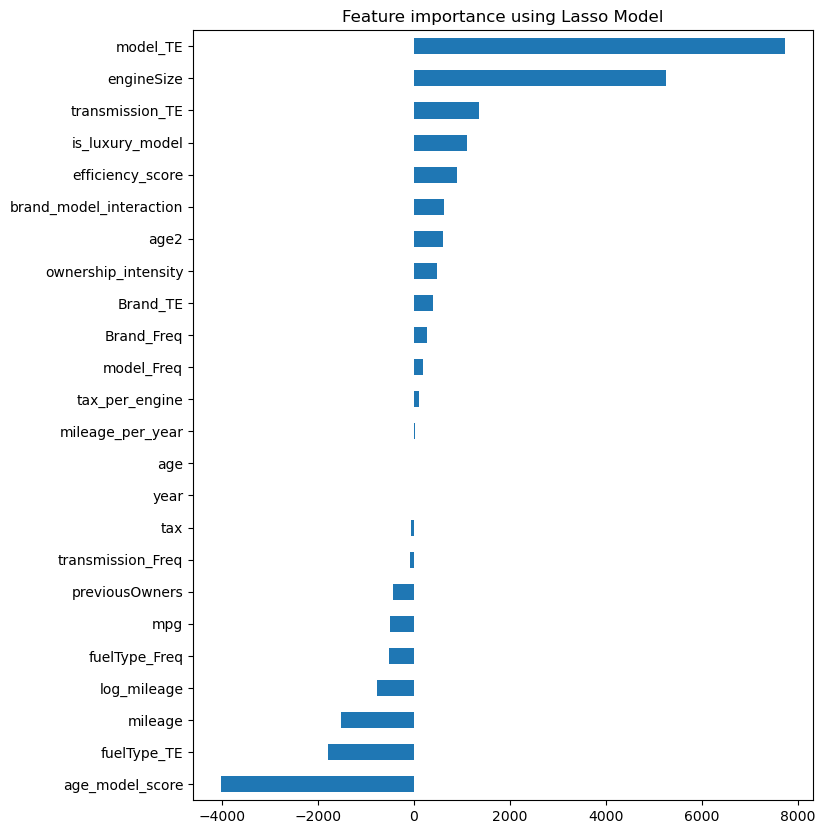

time: 158 ms (started: 2025-12-16 16:51:30 +00:00)


In [132]:
plot_importance(coef,'Lasso')

In [133]:
nof_list = np.arange(1, len(X_train.columns)+1)
best_mae = np.inf
nof = 0
train_mae_list = []
val_mae_list = []

for n in nof_list:
    model = LinearRegression()
    
    # Recursive Feature Elimination
    rfe = RFE(estimator=model, n_features_to_select=n)
    X_train_rfe = rfe.fit_transform(X_train, y_train)
    X_val_rfe = rfe.transform(X_val)
    
    # Fit model
    model.fit(X_train_rfe, y_train)
    
    # Compute MAE for train and validation
    mae_train = mean_absolute_error(y_train, model.predict(X_train_rfe))
    mae_val   = mean_absolute_error(y_val, model.predict(X_val_rfe))
    
    train_mae_list.append(mae_train)
    val_mae_list.append(mae_val)
    
    # Selection criterion: lowest validation MAE
    if mae_val <= best_mae:
        best_mae = mae_val
        nof = n
        features_to_select = pd.Series(rfe.support_, index=X_train.columns)

# Get selected and removed features
selected_features = features_to_select[features_to_select].index.tolist()
removed_features = features_to_select[~features_to_select].index.tolist()

print(f"Optimum number of features: {nof}")
print(f"Validation MAE with {nof} features: {best_mae:.2f}")
print(f"Training MAE with {nof} features: {train_mae_list[nof-1]:.2f}")
print("Selected features:")
print(selected_features)
print("Removed features:")
print(removed_features)

Optimum number of features: 20
Validation MAE with 20 features: 2231.76
Training MAE with 20 features: 2227.41
Selected features:
['mileage', 'mpg', 'engineSize', 'previousOwners', 'age2', 'log_mileage', 'ownership_intensity', 'efficiency_score', 'tax_per_engine', 'is_luxury_model', 'Brand_Freq', 'Brand_TE', 'transmission_Freq', 'transmission_TE', 'fuelType_Freq', 'fuelType_TE', 'model_Freq', 'model_TE', 'brand_model_interaction', 'age_model_score']
Removed features:
['year', 'tax', 'age', 'mileage_per_year']
time: 30.7 s (started: 2025-12-16 16:51:30 +00:00)


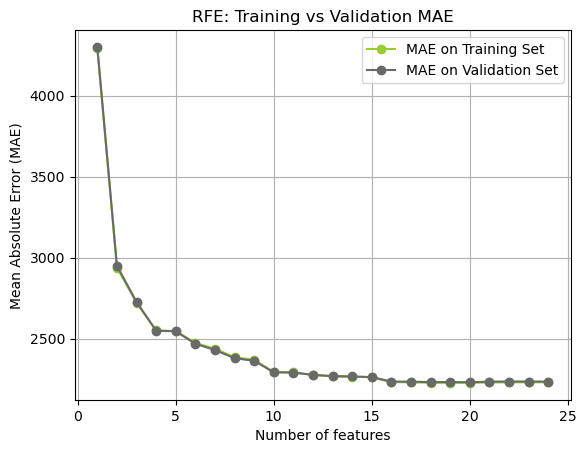

time: 88.3 ms (started: 2025-12-16 16:52:01 +00:00)


In [134]:
plt.plot(range(1, len(train_mae_list) + 1), train_mae_list, label="MAE on Training Set", color='yellowgreen', marker='o')
plt.plot(range(1, len(val_mae_list) + 1), val_mae_list, label="MAE on Validation Set", color='dimgray', marker='o')
plt.xlabel("Number of features")
plt.ylabel("Mean Absolute Error (MAE)")
plt.title("RFE: Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

**We tried using RFE with a SVM for Regression but since it was too computationally expensive (took more than 1 hour to run) we decided to only use RFE with LR.**

In [135]:
anova_reg = SelectKBest(score_func=f_regression, k='all')  # 'all' to get all scores, we’ll choose later
anova_reg.fit(X_train, y_train)

f_scores = anova_reg.scores_
p_values = anova_reg.pvalues_

# Combine into a DataFrame
anova_summary = pd.DataFrame({
    'F_score': f_scores,
    'p_value': p_values
}, index=X_train.columns)

# Sort features by F-score (descending)
anova_summary = anova_summary.sort_values(by='F_score', ascending=False)

# Optional: add selection flag for top k
k = 20
anova_summary['Selected'] = anova_summary.index.isin(anova_summary.head(k).index)

anova = (
    anova_summary.head(25)
    .style
    .background_gradient(subset=['F_score'], cmap='Blues')      # Blue gradient for F-scores
    .format({'F_score': '{:.2f}', 'p_value': '{:.4f}'})         # No scientific notation
)
anova

,F_score,p_value,Selected
model_TE,72590.48,0.0000,True
brand_model_interaction,60239.75,0.0000,True
engineSize,32102.00,0.0000,True
transmission_TE,22774.38,0.0000,True
Brand_TE,21700.27,0.0000,True
transmission_Freq,17444.52,0.0000,True
age,15760.72,0.0000,True
year,15760.72,0.0000,True
is_luxury_model,12781.87,0.0000,True
log_mileage,11689.49,0.0000,True


time: 13.8 ms (started: 2025-12-16 16:52:01 +00:00)


**_We will use a method for Feature Selection which is Mutual Information that checks if our Categorical Features are Statistically Dependent with our Target Feature._**

_For more robustness in checking **RELEVANCY for Prediction** we will perform it 3 different times with different number of neighbors **5**, **10** and **15**._

In [136]:
cat_vars = te_vars + Freq_vars

MI_reg5 = mutual_info_regression(X_train[cat_vars], y_train, n_neighbors = 5, random_state = 15)
dependence_values5 = pd.Series(MI_reg5, index = X_train[cat_vars].columns)

MI_reg10 = mutual_info_regression(X_train[cat_vars], y_train, n_neighbors = 10, random_state = 15)
dependence_values10 = pd.Series(MI_reg10, index = X_train[cat_vars].columns)

MI_reg15 = mutual_info_regression(X_train[cat_vars], y_train, n_neighbors = 15, random_state = 15)
dependence_values15 = pd.Series(MI_reg15, index = X_train[cat_vars].columns)

time: 9.76 s (started: 2025-12-16 16:52:01 +00:00)


In [137]:
MI_comparison = pd.DataFrame({
    'MI_5_neighbors': dependence_values5,
    'MI_10_neighbors': dependence_values10,
    'MI_15_neighbors': dependence_values15
})

MI_comparison['MI_mean'] = MI_comparison.mean(axis=1)

MI_comparison = MI_comparison.sort_values(by='MI_mean', ascending=False)

MI_comparison.style.background_gradient(cmap='Reds').format(precision=4)

,MI_5_neighbors,MI_10_neighbors,MI_15_neighbors,MI_mean
model_TE,0.6591,0.6070,0.5862,0.6174
brand_model_interaction,0.6609,0.6033,0.5742,0.6128
model_Freq,0.5287,0.4393,0.3964,0.4548
Brand_Freq,0.3187,0.2996,0.2875,0.3020
Brand_TE,0.3179,0.2989,0.2861,0.3010
transmission_Freq,0.2471,0.2420,0.2372,0.2421
transmission_TE,0.2429,0.2393,0.2352,0.2391
fuelType_Freq,0.0606,0.0588,0.0574,0.0589
fuelType_TE,0.0631,0.0568,0.0551,0.0584


time: 8.75 ms (started: 2025-12-16 16:52:11 +00:00)


<hr>

### Feature Selection
| Predictor | Spearman | Lasso | RFE LR | ANOVA | Mutual Information | What to do? | 
| --- | --- | --- | --- |--- |--- |---|
| engineSize | Relevant | Keep | Keep | Keep | - |Keep | 
| year | Relevant | Discard | Discard | Keep | - | Discard |
| age | Relevant | Discard | Discard | Keep | - | Discard |
| previousOwners | Irrelevant | Keep | Keep | Irrelevant | - | Discard |
| mpg | Relevant| Keep | Keep | Keep | - | Keep |
| tax | Relevant| Discard | Discard | Keep | - | Try with and without| 
| mileage | Relevant| Keep |Keep |Keep | - | Keep| 
| log_mileage | Relevant | Keep |Keep |Keep | - | Discard | 
| mileage_per_year | Relevant| Discard | Discard |Keep | - | Discard | 
| ownership_intensity | Relevant | Keep |Discard |Keep | - | Try with and without| 
| tax_per_engine | Irrelevant | Keep |Discard|Discard| - | Discard| 
| efficiency_score | Relevant | Keep |Keep |Keep | - | Keep |  
| Brand_TE| Relevant | Keep |Keep |Keep | Relevant | Keep|
| model_TE | Relevant | Keep |Keep |Keep | Relevant | Keep |
| fuelType_TE| Relevant | Keep |Keep |Keep | Irrelevant | Try with and without | 
| transmission_TE| Relevant | Keep |Keep |Keep | Relevant | Keep |  
| Brand_Freq| Irrelevant | Keep |Discard |Discard | Relevant | Discard |
| model_Freq | Irrelevant | Keep |Keep |Keep | Relevant | Keep |
| fuelType_Freq| Relevant | Keep |Keep |Keep | Irrelevant | Discard | 
| transmission_Freq| Relevant | Discard |Keep |Discard | Relevant | Discard | 
| brand_model_interaction | Keep | Keep | Keep | Keep | Relevant | Keep |
| age_model_score | Keep | Keep | Keep | Discard | - | Keep |
| age2 | Keep | Keep | Keep | Keep | - | Keep |

<hr>

In [138]:
vars_to_drop = ['age','previousOwners','year','log_mileage','tax_per_engine','mileage_per_year',
                'Brand_Freq','transmission_Freq','fuelType_Freq']

X_train.drop(vars_to_drop,axis=1,inplace=True)
X_val.drop(vars_to_drop,axis=1,inplace=True)

time: 3.51 ms (started: 2025-12-16 16:52:11 +00:00)


In [139]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53178 entries, 62084 to 70885
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mileage                  53178 non-null  float64
 1   tax                      53178 non-null  float64
 2   mpg                      53178 non-null  float64
 3   engineSize               53178 non-null  float64
 4   age2                     53178 non-null  float64
 5   ownership_intensity      53178 non-null  float64
 6   efficiency_score         53178 non-null  float64
 7   is_luxury_model          53178 non-null  float64
 8   Brand_TE                 53178 non-null  float64
 9   transmission_TE          53178 non-null  float64
 10  fuelType_TE              53178 non-null  float64
 11  model_Freq               53178 non-null  float64
 12  model_TE                 53178 non-null  float64
 13  brand_model_interaction  53178 non-null  float64
 14  age_model_score        

In [140]:
X_train.head()

,mileage,tax,mpg,engineSize,age2,ownership_intensity,efficiency_score,is_luxury_model,Brand_TE,transmission_TE,fuelType_TE,model_Freq,model_TE,brand_model_interaction,age_model_score
carID,,,,,,,,,,,,,,,
62084,1.105710,0.00,-0.060606,0.50,1.800000,-0.692308,-0.342577,0.0,-0.371145,0.0,1.0,-0.442465,-0.584384,-0.321240,0.592227
55404,0.976155,-7.25,0.890909,-0.75,1.066667,-0.692308,1.730016,0.0,-0.163729,0.0,0.0,-0.009148,-0.801480,-0.338561,0.107677
20728,-0.036741,0.00,0.787879,0.50,0.000000,0.538462,0.000000,0.0,-0.151287,0.0,1.0,1.870968,-0.255379,-0.126064,0.119181
29780,0.085795,-5.75,0.206061,-0.50,1.066667,-0.323077,0.706362,0.0,-0.151287,0.0,0.0,-0.392393,0.073889,0.000210,1.119107
3847,0.667308,-6.25,0.987879,0.00,0.000000,-0.076923,0.512643,0.0,0.848713,0.0,1.0,-0.035147,0.185816,0.595993,0.425043


time: 9.37 ms (started: 2025-12-16 16:52:11 +00:00)


## Modeling and Assessment

*Train, tune, and evaluate models to assess predictive performance.*

### Linear Regression

In [141]:
lr_model = LinearRegression()

time: 194 μs (started: 2025-12-16 16:52:11 +00:00)


In [142]:
lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


time: 97.5 ms (started: 2025-12-16 16:52:11 +00:00)


In [143]:
y_pred_train_LR = lr_model.predict(X_train)
y_pred_val_LR = lr_model.predict(X_val)

time: 4.17 ms (started: 2025-12-16 16:52:11 +00:00)


In [144]:
calculate_metrics(y_pred_train_LR,y_pred_val_LR,model_name='Linear Regression')

LINEAR REGRESSION METRICS

TRAIN SET METRICS:
  R² Score:              0.8522
  Adjusted R² Score:     0.8521
  MAE:                   2274.6504
  MSE:                   14081137.5535
  RMSE:                  3752.4842
  Median AE:             1506.4418
  MAPE:                  0.1499

VALIDATION SET METRICS:
  R² Score:              0.8590
  Adjusted R² Score:     0.8589
  MAE:                   2275.5278
  MSE:                   13219959.4261
  RMSE:                  3635.9262
  Median AE:             1503.5129
  MAPE:                  0.1497

MAE COMPARISON
  Train MAE:             2274.6504
  Validation MAE:        2275.5278
  Difference:            0.8774
  % Difference:          0.04%
time: 6.13 ms (started: 2025-12-16 16:52:11 +00:00)


### KNN Regressor

In [145]:
'run_optuna(KNN_RS)'

'run_optuna(KNN_RS)'

time: 1.28 ms (started: 2025-12-16 16:52:11 +00:00)


In [146]:
knn_model = KNeighborsRegressor(n_neighbors = 9, weights = 'uniform', p = 1, leaf_size=14)
knn_model.fit(X_train, y_train)

,n_neighbors,9
,weights,'uniform'
,algorithm,'auto'
,leaf_size,14
,p,1
,metric,'minkowski'
,metric_params,None
,n_jobs,None


time: 62.4 ms (started: 2025-12-16 16:52:11 +00:00)


In [147]:
y_pred_train_KNN = knn_model.predict(X_train)
y_pred_val_KNN = knn_model.predict(X_val)

time: 10 s (started: 2025-12-16 16:52:11 +00:00)


In [148]:
calculate_metrics(y_pred_train_KNN,y_pred_val_KNN,model_name='KNN Regression')

KNN REGRESSION METRICS

TRAIN SET METRICS:
  R² Score:              0.9380
  Adjusted R² Score:     0.9380
  MAE:                   1356.1594
  MSE:                   5902891.8784
  RMSE:                  2429.5868
  Median AE:             826.5556
  MAPE:                  0.0827

VALIDATION SET METRICS:
  R² Score:              0.9327
  Adjusted R² Score:     0.9327
  MAE:                   1507.0866
  MSE:                   6310140.2715
  RMSE:                  2511.9993
  Median AE:             937.1111
  MAPE:                  0.0923

MAE COMPARISON
  Train MAE:             1356.1594
  Validation MAE:        1507.0866
  Difference:            150.9272
  % Difference:          11.13%
time: 6.07 ms (started: 2025-12-16 16:52:21 +00:00)


In [149]:
'run_optuna(DT_RS)'

'run_optuna(DT_RS)'

time: 985 μs (started: 2025-12-16 16:52:21 +00:00)


In [150]:
dtr_model = DecisionTreeRegressor(max_depth = 15, min_samples_split = 31, 
                                  min_samples_leaf = 6,max_features=None,ccp_alpha=0.007741966529901614,random_state=84)
dtr_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,15
,min_samples_split,31
,min_samples_leaf,6
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,84
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.007741966529901614


time: 254 ms (started: 2025-12-16 16:52:21 +00:00)


In [151]:
y_pred_train_DTR = dtr_model.predict(X_train)
y_pred_val_DTR = dtr_model.predict(X_val)

time: 11.3 ms (started: 2025-12-16 16:52:21 +00:00)


In [152]:
calculate_metrics(y_pred_train_DTR,y_pred_val_DTR,model_name='DT Regression')

DT REGRESSION METRICS

TRAIN SET METRICS:
  R² Score:              0.9469
  Adjusted R² Score:     0.9469
  MAE:                   1317.9673
  MSE:                   5059506.2842
  RMSE:                  2249.3346
  Median AE:             833.8410
  MAPE:                  0.0821

VALIDATION SET METRICS:
  R² Score:              0.9090
  Adjusted R² Score:     0.9089
  MAE:                   1583.9097
  MSE:                   8530895.2898
  RMSE:                  2920.7696
  Median AE:             977.7451
  MAPE:                  0.0980

MAE COMPARISON
  Train MAE:             1317.9673
  Validation MAE:        1583.9097
  Difference:            265.9424
  % Difference:          20.18%
time: 6.42 ms (started: 2025-12-16 16:52:21 +00:00)


### Random Forest Regressor

In [153]:
'run_optuna(RFR_RS, n_trials = 100)'

'run_optuna(RFR_RS, n_trials = 100)'

time: 1 ms (started: 2025-12-16 16:52:21 +00:00)


In [154]:
rfr_model = RandomForestRegressor(n_estimators = 214, max_depth = 28, min_samples_split = 28, min_samples_leaf = 3, random_state=84,
                                 max_features=0.5, bootstrap = False, min_impurity_decrease = 0.0008114494044945954)
rfr_model.fit(X_train, y_train)

,n_estimators,214
,criterion,'squared_error'
,max_depth,28
,min_samples_split,28
,min_samples_leaf,3
,min_weight_fraction_leaf,0.0
,max_features,0.5
,max_leaf_nodes,None
,min_impurity_decrease,0.0008114494044945954
,bootstrap,False
,oob_score,False


time: 28.9 s (started: 2025-12-16 16:52:21 +00:00)


In [155]:
y_pred_train_RFR = rfr_model.predict(X_train)
y_pred_val_RFR = rfr_model.predict(X_val)

time: 2.07 s (started: 2025-12-16 16:52:50 +00:00)


In [156]:
calculate_metrics(y_pred_train_RFR,y_pred_val_RFR,model_name='RFR Regression')

RFR REGRESSION METRICS

TRAIN SET METRICS:
  R² Score:              0.9680
  Adjusted R² Score:     0.9680
  MAE:                   988.2090
  MSE:                   3046038.5433
  RMSE:                  1745.2904
  Median AE:             634.5239
  MAPE:                  0.0620

VALIDATION SET METRICS:
  R² Score:              0.9528
  Adjusted R² Score:     0.9527
  MAE:                   1282.4236
  MSE:                   4427640.4328
  RMSE:                  2104.1959
  Median AE:             813.6426
  MAPE:                  0.0804

MAE COMPARISON
  Train MAE:             988.2090
  Validation MAE:        1282.4236
  Difference:            294.2146
  % Difference:          29.77%
time: 6.28 ms (started: 2025-12-16 16:52:52 +00:00)


### Extra Trees Regressor

In [157]:
'run_optuna(ETR_RS, n_trials=100)'

'run_optuna(ETR_RS, n_trials=100)'

time: 995 μs (started: 2025-12-16 16:52:52 +00:00)


In [158]:
etr_model = ExtraTreesRegressor(n_estimators=443,min_samples_split=10,min_samples_leaf=2,max_features=1.0,
                               bootstrap=True, min_impurity_decrease=0.0013186633777016652,
                                ccp_alpha= 5.575402780439288e-05,max_depth=None,random_state= 84)

etr_model.fit(X_train,y_train)

,n_estimators,443
,criterion,'squared_error'
,max_depth,None
,min_samples_split,10
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0013186633777016652
,bootstrap,True
,oob_score,False


time: 21.3 s (started: 2025-12-16 16:52:52 +00:00)


In [159]:
y_pred_train_ETR = etr_model.predict(X_train)
y_pred_val_ETR = etr_model.predict(X_val)

time: 4.94 s (started: 2025-12-16 16:53:14 +00:00)


In [160]:
calculate_metrics(y_pred_train_ETR,y_pred_val_ETR,model_name='ETR Regression')

ETR REGRESSION METRICS

TRAIN SET METRICS:
  R² Score:              0.9662
  Adjusted R² Score:     0.9662
  MAE:                   1011.3637
  MSE:                   3221330.8795
  RMSE:                  1794.8066
  Median AE:             651.5425
  MAPE:                  0.0641

VALIDATION SET METRICS:
  R² Score:              0.9520
  Adjusted R² Score:     0.9519
  MAE:                   1301.9222
  MSE:                   4502165.4998
  RMSE:                  2121.8307
  Median AE:             831.3706
  MAPE:                  0.0819

MAE COMPARISON
  Train MAE:             1011.3637
  Validation MAE:        1301.9222
  Difference:            290.5586
  % Difference:          28.73%
time: 7.01 ms (started: 2025-12-16 16:53:19 +00:00)


### Gradient Boosting

In [161]:
'run_optuna(GBR_RS, n_trials=100)'

'run_optuna(GBR_RS, n_trials=100)'

time: 2.03 ms (started: 2025-12-16 16:53:19 +00:00)


In [162]:
gbr_model = GradientBoostingRegressor(
    n_estimators=487,
    learning_rate=0.0707135736470294,
    max_depth=9,
    min_samples_split=49,
    min_samples_leaf=22,
    max_features=0.5,
    subsample=0.8494826947978215,
    min_impurity_decrease=0.00422568309264799,
    loss='huber',
    alpha = 0.772916547244727,
    random_state=84
)

gbr_model.fit(X_train, y_train)

,loss,'huber'
,learning_rate,0.0707135736470294
,n_estimators,487
,subsample,0.8494826947978215
,criterion,'friedman_mse'
,min_samples_split,49
,min_samples_leaf,22
,min_weight_fraction_leaf,0.0
,max_depth,9
,min_impurity_decrease,0.00422568309264799
,init,None


time: 54.6 s (started: 2025-12-16 16:53:19 +00:00)


In [163]:
y_pred_train_GBR = gbr_model.predict(X_train)
y_pred_val_GBR = gbr_model.predict(X_val)

time: 852 ms (started: 2025-12-16 16:54:13 +00:00)


In [164]:
calculate_metrics(y_pred_train_GBR,y_pred_val_GBR,model_name='GBR Regression')

GBR REGRESSION METRICS

TRAIN SET METRICS:
  R² Score:              0.9601
  Adjusted R² Score:     0.9601
  MAE:                   996.9255
  MSE:                   3801551.3587
  RMSE:                  1949.7567
  Median AE:             622.5400
  MAPE:                  0.0620

VALIDATION SET METRICS:
  R² Score:              0.9547
  Adjusted R² Score:     0.9546
  MAE:                   1231.1262
  MSE:                   4251219.1708
  RMSE:                  2061.8485
  Median AE:             785.4014
  MAPE:                  0.0754

MAE COMPARISON
  Train MAE:             996.9255
  Validation MAE:        1231.1262
  Difference:            234.2007
  % Difference:          23.49%
time: 6.68 ms (started: 2025-12-16 16:54:14 +00:00)


### Neural Network

In [165]:
'run_optuna(MLP_RS,n_trials=100)'

'run_optuna(MLP_RS,n_trials=100)'

time: 1.32 ms (started: 2025-12-16 16:54:14 +00:00)


In [166]:
mlp_model = MLPRegressor(random_state=84, 
                         hidden_layer_sizes=(157,117,34),
                         activation='relu',solver='adam', 
                         alpha= 0.0006716114667865268,
                         learning_rate_init=0.014590595085209494,
                         beta_1 = 0.8972688239685336,
                         beta_2 = 0.9598931459649113,
                         max_iter=622, batch_size=256,verbose=2)

time: 463 μs (started: 2025-12-16 16:54:14 +00:00)


In [167]:
mlp_model.fit(X_train,y_train)

Iteration 1, loss = 26775589.09801109
Iteration 2, loss = 6058213.60345580
Iteration 3, loss = 5713848.49649794
Iteration 4, loss = 5562910.51930222
Iteration 5, loss = 5402809.28985469
Iteration 6, loss = 5358335.25194374
Iteration 7, loss = 5222232.57937993
Iteration 8, loss = 5160002.87205292
Iteration 9, loss = 5024425.94530465
Iteration 10, loss = 4893470.41078417
Iteration 11, loss = 4896736.56875472
Iteration 12, loss = 4750064.05092460
Iteration 13, loss = 4634863.97752198
Iteration 14, loss = 4597339.23296908
Iteration 15, loss = 4490912.11419984
Iteration 16, loss = 4438060.83394375
Iteration 17, loss = 4412342.93583374
Iteration 18, loss = 4361391.42026286
Iteration 19, loss = 4308941.72566372
Iteration 20, loss = 4196832.62757703
Iteration 21, loss = 4170147.14308016
Iteration 22, loss = 4095328.99299567
Iteration 23, loss = 4097179.24330759
Iteration 24, loss = 4087018.49435933
Iteration 25, loss = 3959226.39021421
Iteration 26, loss = 3899601.93537161
Iteration 27, loss =

,loss,'squared_error'
,hidden_layer_sizes,"(157, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0006716114667865268
,batch_size,256
,learning_rate,'constant'
,learning_rate_init,0.014590595085209494
,power_t,0.5
,max_iter,622
,shuffle,True


time: 4min 12s (started: 2025-12-16 16:54:14 +00:00)


In [168]:
y_pred_train_MLP = mlp_model.predict(X_train)
y_pred_val_MLP = mlp_model.predict(X_val)

time: 183 ms (started: 2025-12-16 16:58:26 +00:00)


In [169]:
calculate_metrics(y_pred_train_MLP,y_pred_val_MLP,model_name='MLP Regression')

MLP REGRESSION METRICS

TRAIN SET METRICS:
  R² Score:              0.9642
  Adjusted R² Score:     0.9642
  MAE:                   1210.8360
  MSE:                   3406245.9350
  RMSE:                  1845.6018
  Median AE:             840.3157
  MAPE:                  0.0767

VALIDATION SET METRICS:
  R² Score:              0.9312
  Adjusted R² Score:     0.9311
  MAE:                   1533.3436
  MSE:                   6451635.2398
  RMSE:                  2540.0069
  Median AE:             973.7966
  MAPE:                  0.0939

MAE COMPARISON
  Train MAE:             1210.8360
  Validation MAE:        1533.3436
  Difference:            322.5076
  % Difference:          26.64%
time: 8.91 ms (started: 2025-12-16 16:58:26 +00:00)


<hr>

### Model Performance Comparison

| Model | Train R² | Val R² | Train MAE | Val MAE | Train MSE | Val MSE | Train RMSE | Val RMSE | Train Median AE | Val Median AE | Train MAPE | Val MAPE | MAE Diff | MAE % Diff |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Linear Regression | 0.8522 | 0.8590 | 2274.65 | 2275.53 | 14081137.55 | 13219959.43 | 3752.48 | 3635.93 | 1506.44 | 1503.51 | 0.1499 | 0.1497 | 0.88 | 0.04% |
| KNN | 0.9380 | 0.9327 | 1356.16 | 1507.09 | 5902891.88 | 6310140.27 | 2429.59 | 2512.00 | 826.56 | 937.11 | 0.0827 | 0.0923 | 150.93 | 11.13% |
| Decision Tree | 0.9469 | 0.9090 | 1317.97 | 1583.91 | 5059506.28 | 8530895.29 | 2249.33 | 2920.77 | 833.84 | 977.75 | 0.0821 | 0.0980 | 265.94 | 20.18% |
| Random Forest | 0.9680 | 0.9528 | 988.21 | 1282.42 | 3046038.54 | 4427640.43 | 1745.29 | 2104.20 | 634.52 | 813.64 | 0.0620 | 0.0804 | 294.21 | 29.77% |
| Extra Trees | 0.9662 | 0.9520 | 1011.36 | 1301.92 | 3221330.88 | 4502165.50 | 1794.81 | 2121.83 | 651.54 | 831.37 | 0.0641 | 0.0819 | 290.56 | 28.73% |
| Gradient Boosting | 0.9601 | 0.9547 | 996.93 | 1231.12 | 3801551.36 | 4251219.17 | 1949.76 | 2061.85 | 622.54 | 785.40 | 0.0620 | 0.0754 | 234.20 | 23.49% |
| MLP | 0.9642 | 0.9312 | 1210.84 | 1533.34 | 3406245.94 | 6451635.24 | 1845.60 | 2540.01 | 840.32 | 973.80 | 0.0767 | 0.0939 | 322.51 | 26.64% |

<hr>

*The Gradient Boosting model beats the remaining ones in almost every metric, followed by the Random Forest. To try to obtain a better model we will create an ensebmle model combining different individual ones. As the two best models are tree based, to have some diversity we will combine them with KNN and MLP.*

### Ensemble Learner

In [170]:
class WeightedEnsemble:
    """
    Weighted ensemble with equal weights or manual weights.
    """
    
    def __init__(self, models, weights=None):
        
        self.models = models
        self.weights = weights
        
    def fit(self, X_train, y_train):
        """Train all models on training data only"""
        for name, model in self.models:
            print(f"Training {name}...")
            model.fit(X_train, y_train)
        
        # Set equal weights if not provided
        if self.weights is None:
            self.weights = np.ones(len(self.models)) / len(self.models)
            print(f"Using equal weights: {dict(zip([n for n, _ in self.models], self.weights))}")
        else:
            # Normalize provided weights
            self.weights = np.array(self.weights)
            self.weights = self.weights / self.weights.sum()
            print(f"Using provided weights: {dict(zip([n for n, _ in self.models], self.weights))}")
            
        return self
    
    def predict(self, X):
        """Weighted average of predictions"""
        predictions = np.column_stack([
            model.predict(X) for name, model in self.models
        ])
        return predictions @ self.weights

time: 1.44 ms (started: 2025-12-16 16:58:26 +00:00)


In [171]:
models = [
    ('knn',knn_model),
    ('rf', rfr_model),
    ('gb', gbr_model),
    ('mlp',mlp_model)
]

time: 423 μs (started: 2025-12-16 16:58:26 +00:00)


In [172]:
"""weight_candidates = [
    [0.10, 0.30, 0.45, 0.15],  # Original
    [0.05, 0.30, 0.50, 0.15],  # More weight to GBR
    [0.08, 0.27, 0.50, 0.15],  # Even more to GBR
    [0.10, 0.25, 0.50, 0.15],  # Max GBR
    [0.05, 0.35, 0.45, 0.15],  # More to RF
    [0.00, 0.35, 0.50, 0.15],  # Drop KNN completely
]

best_mae = float('inf')
best_weights = None

for weights in weight_candidates:
    ensemble = WeightedEnsemble(models, weights=weights)
    ensemble.fit(X_train, y_train)
    mae = mean_absolute_error(y_val, ensemble.predict(X_val))
    print(f"Weights {weights} → MAE: {mae:.2f}")
    
    if mae < best_mae:
        best_mae = mae
        best_weights = weights

print(f"\n Best weights: {best_weights}")
print(f"Best MAE: {best_mae:.2f}")"""

'weight_candidates = [\n    [0.10, 0.30, 0.45, 0.15],  # Original\n    [0.05, 0.30, 0.50, 0.15],  # More weight to GBR\n    [0.08, 0.27, 0.50, 0.15],  # Even more to GBR\n    [0.10, 0.25, 0.50, 0.15],  # Max GBR\n    [0.05, 0.35, 0.45, 0.15],  # More to RF\n    [0.00, 0.35, 0.50, 0.15],  # Drop KNN completely\n]\n\nbest_mae = float(\'inf\')\nbest_weights = None\n\nfor weights in weight_candidates:\n    ensemble = WeightedEnsemble(models, weights=weights)\n    ensemble.fit(X_train, y_train)\n    mae = mean_absolute_error(y_val, ensemble.predict(X_val))\n    print(f"Weights {weights} → MAE: {mae:.2f}")\n    \n    if mae < best_mae:\n        best_mae = mae\n        best_weights = weights\n\nprint(f"\n Best weights: {best_weights}")\nprint(f"Best MAE: {best_mae:.2f}")'

time: 1.85 ms (started: 2025-12-16 16:58:26 +00:00)


*Best weights - [0.0 for KNN, 0.35 for RFR, 0.5 for GBR, 0.15 for MLP], with MAE = 1234.76 (worse than individual Gradient Boosting)*

In [173]:
models_best_only = [
    ('gb', gbr_model),  # 1231
    ('rf', rfr_model),  # 1282
    # Drop MLP (1533) and KNN (1507)
]

"""
weight_candidates = [
    [0.60, 0.40],  # More GBR
    [0.65, 0.35],  # More GBR
    [0.70, 0.30],  # Even more GBR
    [0.55, 0.45],  # More RF
    [0.50, 0.50],  # Equal weights
]

best_mae = float('inf')
best_weights = None

for weights in weight_candidates:
    ensemble = WeightedEnsemble(models_best_only, weights=weights)
    ensemble.fit(X_train, y_train)
    mae = mean_absolute_error(y_val, ensemble.predict(X_val))
    print(f"Weights {weights} → MAE: {mae:.2f}")
    
    if mae < best_mae:
        best_mae = mae
        best_weights = weights

print(f"\n Best weights: {best_weights}")
print(f"Best MAE: {best_mae:.2f}")"""

'\nweight_candidates = [\n    [0.60, 0.40],  # More GBR\n    [0.65, 0.35],  # More GBR\n    [0.70, 0.30],  # Even more GBR\n    [0.55, 0.45],  # More RF\n    [0.50, 0.50],  # Equal weights\n]\n\nbest_mae = float(\'inf\')\nbest_weights = None\n\nfor weights in weight_candidates:\n    ensemble = WeightedEnsemble(models_best_only, weights=weights)\n    ensemble.fit(X_train, y_train)\n    mae = mean_absolute_error(y_val, ensemble.predict(X_val))\n    print(f"Weights {weights} → MAE: {mae:.2f}")\n    \n    if mae < best_mae:\n        best_mae = mae\n        best_weights = weights\n\nprint(f"\n Best weights: {best_weights}")\nprint(f"Best MAE: {best_mae:.2f}")'

time: 2.04 ms (started: 2025-12-16 16:58:26 +00:00)


*Best weights - [0.7 for GBR, 0.3 for RFR], with MAE = 1224.76 (better than individual Gradient Boosting)*

In [174]:
"""weight_tests = [
    ([1.00, 0.00], "GBR only"),
    ([0.95, 0.05], "95/5"),
    ([0.90, 0.10], "90/10"),
    ([0.85, 0.15], "85/15"),
    ([0.80, 0.20], "80/20"),
    ([0.70, 0.30], "70/30"),
    ([0.60, 0.40], "60/40"),
]

results = []

for weights, label in weight_tests:
    if weights[0] == 1.0:
        # Just GBR
        pred = gbr_model.predict(X_val)
    else:
        ensemble = WeightedEnsemble(models_best_only, weights=weights)
        ensemble.fit(X_train, y_train)
        pred = ensemble.predict(X_val)
    
    mae = mean_absolute_error(y_val, pred)
    improvement = 1231 - mae  # vs GBR baseline
    
    results.append({
        'weights': label,
        'mae': mae,
        'improvement': improvement,
        'worth_it': 'Improvment' if improvement > 2 else ('Slight Improvment' if improvement > 1 else 'No Improvment')
    })
    
    print(f"{label:15s} MAE: {mae:.2f}  Improvement: {improvement:+.2f}  {results[-1]['worth_it']}")"""

'weight_tests = [\n    ([1.00, 0.00], "GBR only"),\n    ([0.95, 0.05], "95/5"),\n    ([0.90, 0.10], "90/10"),\n    ([0.85, 0.15], "85/15"),\n    ([0.80, 0.20], "80/20"),\n    ([0.70, 0.30], "70/30"),\n    ([0.60, 0.40], "60/40"),\n]\n\nresults = []\n\nfor weights, label in weight_tests:\n    if weights[0] == 1.0:\n        # Just GBR\n        pred = gbr_model.predict(X_val)\n    else:\n        ensemble = WeightedEnsemble(models_best_only, weights=weights)\n        ensemble.fit(X_train, y_train)\n        pred = ensemble.predict(X_val)\n    \n    mae = mean_absolute_error(y_val, pred)\n    improvement = 1231 - mae  # vs GBR baseline\n    \n    results.append({\n        \'weights\': label,\n        \'mae\': mae,\n        \'improvement\': improvement,\n        \'worth_it\': \'Improvment\' if improvement > 2 else (\'Slight Improvment\' if improvement > 1 else \'No Improvment\')\n    })\n    \n    print(f"{label:15s} MAE: {mae:.2f}  Improvement: {improvement:+.2f}  {results[-1][\'worth_it\']}

time: 2.47 ms (started: 2025-12-16 16:58:26 +00:00)


*Best weights - [0.8 for GBR, 0.2 for RFR], with MAE = 1224.48 (better than individual Gradient Boosting)*

In [175]:
ensemble = WeightedEnsemble(models_best_only, weights=[0.80, 0.20])
ensemble.fit(X_train, y_train)

Training gb...
Training rf...
Using provided weights: {'gb': np.float64(0.8), 'rf': np.float64(0.2)}


time: 1min 26s (started: 2025-12-16 16:58:26 +00:00)


In [176]:
y_pred_train_ENS = ensemble.predict(X_train)
y_pred_val_ENS = ensemble.predict(X_val)
calculate_metrics(y_pred_train_ENS,y_pred_val_ENS,model_name='Ensemble')

ENSEMBLE METRICS

TRAIN SET METRICS:
  R² Score:              0.9628
  Adjusted R² Score:     0.9628
  MAE:                   980.0983
  MSE:                   3541812.0952
  RMSE:                  1881.9703
  Median AE:             618.0288
  MAPE:                  0.0610

VALIDATION SET METRICS:
  R² Score:              0.9558
  Adjusted R² Score:     0.9557
  MAE:                   1224.4789
  MSE:                   4146463.8822
  RMSE:                  2036.2868
  Median AE:             784.1441
  MAPE:                  0.0753

MAE COMPARISON
  Train MAE:             980.0983
  Validation MAE:        1224.4789
  Difference:            244.3806
  % Difference:          24.93%
time: 2.99 s (started: 2025-12-16 16:59:53 +00:00)


*Comparing with the other individual models, the ensemble with the Gradient Boosting Regressor and Random Forests Regressor obtained the best results, as such it will be the chosen model to obtain the predictions*

#  Model Deployment

In [177]:
test = pd.read_csv('data/test.csv')

time: 31 ms (started: 2025-12-16 16:59:56 +00:00)


In [178]:
test_data = test.copy()

time: 963 μs (started: 2025-12-16 16:59:56 +00:00)


In [179]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32567 entries, 0 to 32566
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   carID           32567 non-null  int64  
 1   Brand           31918 non-null  object 
 2   model           31917 non-null  object 
 3   year            31914 non-null  float64
 4   transmission    31944 non-null  object 
 5   mileage         31878 non-null  float64
 6   fuelType        31911 non-null  object 
 7   tax             29259 non-null  float64
 8   mpg             29279 non-null  float64
 9   engineSize      31939 non-null  float64
 10  paintQuality%   31942 non-null  float64
 11  previousOwners  31970 non-null  float64
 12  hasDamage       31970 non-null  float64
dtypes: float64(8), int64(1), object(4)
memory usage: 3.2+ MB
time: 9.25 ms (started: 2025-12-16 16:59:56 +00:00)


*The preprocessing performed on the training set will now have to be applied in the same way for the test set.*

In [180]:
test_data.drop_duplicates(subset=test_data.columns.difference(['carID']), inplace=True)

time: 15.1 ms (started: 2025-12-16 16:59:56 +00:00)


In [181]:
test_data.set_index('carID', inplace = True)

time: 665 μs (started: 2025-12-16 16:59:56 +00:00)


In [182]:
test_data.drop(columns='hasDamage',inplace = True)

time: 4.71 ms (started: 2025-12-16 16:59:56 +00:00)


In [183]:
test_data['Brand'] = test_data['Brand'].replace(brand_mapping)
test_data['Brand'].value_counts()

Brand
Ford        6888
Mercedes    5006
VW          4466
Opel        4008
BMW         3172
Audi        3130
Toyota      1982
Skoda       1839
Hyundai     1427
Name: count, dtype: int64

time: 63 ms (started: 2025-12-16 16:59:56 +00:00)


In [184]:
test_data['model'] = (
    test_data['model']
    .astype(str)
    .str.lower()                        # lowercase everything
    .str.strip()                        # remove leading/trailing spaces
    .str.replace(r'[^a-z0-9 ]', '', regex=True)  # remove special chars except space
)

test_data['model'] = test_data['model'].replace(model_mapping)

test_data['model'] = test_data['model'].apply(fuzzy_match_model)

test_data['model'] = test_data['model'].str.title()

test_data['model'] = test_data['model'].replace(rare_models, 'Other')

time: 1.37 s (started: 2025-12-16 16:59:56 +00:00)


In [185]:
test_data['transmission'] = test_data['transmission'].replace(transmission_mapping)
test_data['transmission'].value_counts()

transmission
Manual       17889
Semi-Auto     7267
Automatic     6440
Unknown        348
Name: count, dtype: int64

time: 44.1 ms (started: 2025-12-16 16:59:58 +00:00)


In [186]:
test_data['fuelType'] = test_data['fuelType'].replace(fuel_mapping)
test_data['fuelType'].value_counts()

fuelType
Petrol    17497
Diesel    13395
Hybrid      936
Other        83
Name: count, dtype: int64

time: 38.1 ms (started: 2025-12-16 16:59:58 +00:00)


In [187]:
test_data['Brand'] = test_data.apply(fill_brand_from_model, axis=1)

time: 235 ms (started: 2025-12-16 16:59:58 +00:00)


In [188]:
test_data['Brand'] = test_data['Brand'].fillna('Missing')
test_data['model'] = test_data['model'].fillna('Missing')
test_data['transmission'] = test_data['transmission'].fillna('Missing')
test_data['fuelType'] = test_data['fuelType'].fillna('Missing')

time: 7.1 ms (started: 2025-12-16 16:59:58 +00:00)


In [189]:
test_data['year'] = test_data['year'].apply(lambda x: int(x) if pd.notnull(x) else x)
test_data.loc[test_data['year'] > 2020, 'year'] = np.nan
test_data.loc[test_data['mileage'] < 0, 'mileage'] = np.nan
test_data.loc[test_data['tax'] < 0, 'tax'] = np.nan
test_data.loc[test_data['engineSize'] <= 0, 'engineSize'] = np.nan
test_data.loc[test_data['previousOwners'] < 0, 'previousOwners'] = np.nan
test_data['previousOwners'] = test_data['previousOwners'].apply(lambda x: int(x) if pd.notnull(x) else x)
test_data.loc[test_data['mpg'] <= 0, 'mpg'] = np.nan

time: 54.2 ms (started: 2025-12-16 16:59:58 +00:00)


In [190]:
test_data.drop('paintQuality%',axis = 1, inplace = True)

time: 3.74 ms (started: 2025-12-16 16:59:58 +00:00)


In [191]:
test_data['age'] = current_year - test_data['year']

time: 780 μs (started: 2025-12-16 16:59:58 +00:00)


In [192]:
test_data['age2'] = test_data['age']**2

time: 904 μs (started: 2025-12-16 16:59:58 +00:00)


In [193]:
test_data['log_mileage'] = np.where(
    test_data['mileage'].notna(),
    np.log1p(test_data['mileage']),
    np.nan
)

time: 2.7 ms (started: 2025-12-16 16:59:58 +00:00)


In [194]:
test_data['mileage_per_year'] = np.where(
    (test_data['age'].notna()) & (test_data['mileage'].notna()),
    np.where(
        test_data['age'] > 0,
        test_data['mileage'] / test_data['age'],   
        test_data['mileage']                   
    ),
    np.nan 
)

time: 1.78 ms (started: 2025-12-16 16:59:58 +00:00)


In [195]:
test_data['ownership_intensity'] = np.where(
    (test_data['age'].notna()) & (test_data['previousOwners'].notna()),
    np.where(
        test_data['age'] > 0,
        test_data['previousOwners'] / test_data['age'], 
        test_data['previousOwners']                  
    ),
    np.nan 
)

time: 2.16 ms (started: 2025-12-16 16:59:58 +00:00)


In [196]:
test_data['efficiency_score'] = np.where(
    (test_data['engineSize'].notna()) & (test_data['engineSize'] != 0),
    test_data['mpg'] / test_data['engineSize'],
    np.nan  # undefined if engineSize missing or zero
)

time: 1.57 ms (started: 2025-12-16 16:59:58 +00:00)


In [197]:
test_data['tax_per_engine'] = np.where(
    (test_data['engineSize'].notna()) & (test_data['engineSize'] != 0),
    test_data['tax'] / test_data['engineSize'],
    np.nan 
)

time: 1.61 ms (started: 2025-12-16 16:59:58 +00:00)


In [198]:
test_data['is_luxury_model'] = test_data['model'].isin(expensive_models).astype(int)

time: 3.56 ms (started: 2025-12-16 16:59:58 +00:00)


In [199]:
global_median_price = y_train.median()

time: 1.72 ms (started: 2025-12-16 16:59:58 +00:00)


In [200]:
test_data['Brand_Freq'] = test_data['Brand'].map(freq_brand).fillna(freq_brand.median())
test_data['Brand_TE'] = test_data['Brand'].map(target_brand).fillna(global_median_price)

test_data['transmission_Freq'] = test_data['transmission'].map(freq_transmission).fillna(freq_transmission.median())
test_data['transmission_TE'] = test_data['transmission'].map(target_transmission).fillna(global_median_price)

test_data['fuelType_Freq'] = test_data['fuelType'].map(freq_fuel).fillna(freq_fuel.median())
test_data['fuelType_TE'] = test_data['fuelType'].map(target_fuelType).fillna(global_median_price)

test_data['model_Freq'] = test_data['model'].map(freq_model).fillna(freq_model.median())
test_data['model_TE'] = test_data['model'].map(target_model).fillna(global_median_price)

time: 17.6 ms (started: 2025-12-16 16:59:58 +00:00)


In [201]:
test_data['brand_model_interaction'] = test_data['Brand_TE'] * test_data['model_TE']

time: 858 μs (started: 2025-12-16 16:59:58 +00:00)


In [202]:
test_data['age_model_score'] = test_data['age'] * test_data['model_TE']

time: 851 μs (started: 2025-12-16 16:59:58 +00:00)


In [203]:
test_data.drop(['Brand', 'transmission', 'fuelType','model'], axis = 1, inplace = True)

time: 4.12 ms (started: 2025-12-16 16:59:58 +00:00)


In [204]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32567 entries, 89856 to 99627
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     31734 non-null  float64
 1   mileage                  31708 non-null  float64
 2   tax                      29098 non-null  float64
 3   mpg                      29262 non-null  float64
 4   engineSize               31813 non-null  float64
 5   previousOwners           31802 non-null  float64
 6   age                      31734 non-null  float64
 7   age2                     31734 non-null  float64
 8   log_mileage              31708 non-null  float64
 9   mileage_per_year         30908 non-null  float64
 10  ownership_intensity      30991 non-null  float64
 11  efficiency_score         28576 non-null  float64
 12  tax_per_engine           28419 non-null  float64
 13  is_luxury_model          32567 non-null  int64  
 14  Brand_Freq             

In [205]:
test_data.head()

,year,mileage,tax,mpg,engineSize,previousOwners,age,age2,log_mileage,mileage_per_year,...,Brand_Freq,Brand_TE,transmission_Freq,transmission_TE,fuelType_Freq,fuelType_TE,model_Freq,model_TE,brand_model_interaction,age_model_score
carID,,,,,,,,,,,,,,,,,,,,,
89856,NaN,30700.0,205.0,41.5,1.6,3.0,NaN,NaN,10.332051,NaN,...,0.044135,12846.772049,0.200873,21495.501966,0.542724,15012.344894,0.004739,11523.000000,1.480334e+08,NaN
106581,2017.0,NaN,150.0,38.2,2.0,2.0,3.0,9.0,NaN,NaN,...,0.140152,16787.239367,0.221257,24321.329764,0.542724,15012.344894,0.016605,22071.494904,3.705195e+08,66214.484711
80886,2016.0,36792.0,125.0,51.4,1.5,2.0,4.0,16.0,10.513063,9198.0,...,0.099327,22702.120030,0.200873,21495.501966,0.542724,15012.344894,0.011640,19705.033926,4.473460e+08,78820.135703
100174,2019.0,5533.0,145.0,44.1,1.2,1.0,1.0,1.0,8.618666,5533.0,...,0.127064,10383.233832,0.548497,12196.221270,0.542724,15012.344894,0.005115,17267.992647,1.792976e+08,17267.992647
81376,2019.0,9058.0,150.0,51.4,2.0,4.0,1.0,1.0,9.111514,9058.0,...,0.099327,22702.120030,0.221257,24321.329764,0.405638,19200.142645,0.017808,15687.822598,3.561468e+08,15687.822598


time: 16.1 ms (started: 2025-12-16 16:59:58 +00:00)


In [206]:
test_scaled = scaler.transform(test_data)
test_data = pd.DataFrame(test_scaled, columns = test_data.columns).set_index(test_data.index)
test_data.head()

,year,mileage,tax,mpg,engineSize,previousOwners,age,age2,log_mileage,mileage_per_year,...,Brand_Freq,Brand_TE,transmission_Freq,transmission_TE,fuelType_Freq,fuelType_TE,model_Freq,model_TE,brand_model_interaction,age_model_score
carID,,,,,,,,,,,,,,,,,,,,,
89856,NaN,0.534946,3.00,-0.775758,0.000,0.5,NaN,NaN,0.390697,NaN,...,-1.638639,-0.130098,-1.062292,1.000000,0.0,0.0,-0.334617,-0.441125,-0.189706,NaN
106581,0.000000,NaN,0.25,-0.975758,0.500,0.0,0.000000,0.000000,NaN,NaN,...,0.000000,0.255459,-1.000000,1.303876,0.0,0.0,-0.030814,0.615844,0.487203,0.723164
80886,-0.333333,0.779295,-1.00,-0.175758,-0.125,0.0,0.333333,0.466667,0.514791,0.416575,...,-0.696727,0.834203,-1.062292,1.000000,0.0,0.0,-0.157920,0.378722,0.720946,1.015049
100174,0.666667,-0.474500,0.00,-0.618182,-0.500,-0.5,-0.666667,-0.533333,-0.783927,-0.224713,...,-0.223363,-0.371145,0.000000,0.000000,0.0,0.0,-0.324988,0.134529,-0.094586,-0.410196
81376,0.666667,-0.333113,0.25,-0.175758,0.500,1.0,-0.666667,-0.533333,-0.446052,0.392078,...,-0.696727,0.834203,-1.000000,1.303876,-1.0,1.0,0.000000,-0.023806,0.443474,-0.446785


time: 16.1 ms (started: 2025-12-16 16:59:58 +00:00)


In [207]:
test_data[all_impute_vars] = imputer.transform(test_data[all_impute_vars])

[IterativeImputer] Completing matrix with shape (32567, 14)
[IterativeImputer] Ending imputation round 1/13, elapsed time 0.01
[IterativeImputer] Ending imputation round 2/13, elapsed time 0.01
[IterativeImputer] Ending imputation round 3/13, elapsed time 0.02
[IterativeImputer] Ending imputation round 4/13, elapsed time 0.03
[IterativeImputer] Ending imputation round 5/13, elapsed time 0.04
[IterativeImputer] Ending imputation round 6/13, elapsed time 0.05
[IterativeImputer] Ending imputation round 7/13, elapsed time 0.06
[IterativeImputer] Ending imputation round 8/13, elapsed time 0.07
[IterativeImputer] Ending imputation round 9/13, elapsed time 0.07
[IterativeImputer] Ending imputation round 10/13, elapsed time 0.08
[IterativeImputer] Ending imputation round 11/13, elapsed time 0.09
[IterativeImputer] Ending imputation round 12/13, elapsed time 0.10
[IterativeImputer] Ending imputation round 13/13, elapsed time 0.11
time: 123 ms (started: 2025-12-16 16:59:58 +00:00)


In [208]:
test_data.isna().sum()

year                       0
mileage                    0
tax                        0
mpg                        0
engineSize                 0
previousOwners             0
age                        0
age2                       0
log_mileage                0
mileage_per_year           0
ownership_intensity        0
efficiency_score           0
tax_per_engine             0
is_luxury_model            0
Brand_Freq                 0
Brand_TE                   0
transmission_Freq          0
transmission_TE            0
fuelType_Freq              0
fuelType_TE                0
model_Freq                 0
model_TE                   0
brand_model_interaction    0
age_model_score            0
dtype: int64

time: 3.97 ms (started: 2025-12-16 16:59:58 +00:00)


In [209]:
vars_to_drop

['age',
 'previousOwners',
 'year',
 'log_mileage',
 'tax_per_engine',
 'mileage_per_year',
 'Brand_Freq',
 'transmission_Freq',
 'fuelType_Freq']

time: 1.38 ms (started: 2025-12-16 16:59:58 +00:00)


In [210]:
test_data.drop(vars_to_drop,axis=1,inplace=True)

time: 2.23 ms (started: 2025-12-16 16:59:58 +00:00)


In [211]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32567 entries, 89856 to 99627
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mileage                  32567 non-null  float64
 1   tax                      32567 non-null  float64
 2   mpg                      32567 non-null  float64
 3   engineSize               32567 non-null  float64
 4   age2                     32567 non-null  float64
 5   ownership_intensity      32567 non-null  float64
 6   efficiency_score         32567 non-null  float64
 7   is_luxury_model          32567 non-null  float64
 8   Brand_TE                 32567 non-null  float64
 9   transmission_TE          32567 non-null  float64
 10  fuelType_TE              32567 non-null  float64
 11  model_Freq               32567 non-null  float64
 12  model_TE                 32567 non-null  float64
 13  brand_model_interaction  32567 non-null  float64
 14  age_model_score        

### Final Predictions on Test Data

In [212]:
labels_test = ensemble.predict(test_data)

time: 1.3 s (started: 2025-12-16 16:59:58 +00:00)


In [213]:
index = test_data.index.T
answer = pd.DataFrame([index, labels_test]).T
answer.columns = ['carID','price']
answer['carID'] = answer['carID'].astype(np.int64)
answer['price'] = answer['price'].astype(np.int64)

answer.head()

,carID,price
0,89856,10021
1,106581,24005
2,80886,13415
3,100174,17338
4,81376,22452


time: 319 ms (started: 2025-12-16 17:00:00 +00:00)


In [214]:
answer.set_index('carID').to_csv('data/final_submission.csv', sep = ',')

time: 33.9 ms (started: 2025-12-16 17:00:00 +00:00)


In [215]:
from IPython.display import FileLink
display(FileLink('data/final_submission.csv'))

/Users/duartecneves/Documents/Faculdade/Mestrado/ML/Project/data/final_submission.csv

time: 1.8 ms (started: 2025-12-16 17:00:00 +00:00)


## Interface for New Inputs

**This command-line interface provides a straightforward way for users to input car details and receive an estimated market price based on final ensemble model.** 

1. **User Input Collection**:
The interface prompts users to enter key vehicle features such as brand, model, year, mileage, fuel type, transmission, tax, engine size, paint quality, previous owners, and damage status. Input validation ensures that entries are of the correct type and not left empty.

2. **Data Processing and Feature Engineering**:
The collected data is cleaned and transformed in same way it was done for our model. This includes mapping categorical values, normalizing text inputs, handling missing or invalid values, creating the new features and encode the categorical variables.

3. **Prediction and Output**:
After preprocessing, the data is scaled and imputed for missing values before being passed to the ensemble regression model that predicts the vehicle’s price. The interface then displays the predicted price along with a confidence interval (the MAE obtained on the validation set), helping users understand the expected price range.

4. **Interactive Workflow**:
Users review their input data before confirming prediction. They can perform multiple predictions in one session or exit as desired. Error handling ensures smooth interaction and guides users to correct invalid inputs.

In [216]:
def get_user_input():
    """
    Interactive interface to collect input data from user.
    
    """
    print("="*60)
    print("PRICE PREDICTION - Please provide the following information:")
    print("="*60)
    
    # Dictionary to store user inputs
    user_data = {}
    
    # List of all features, with descriptions
    features = [
        ('Brand', 'What is the brand of your car?', str),
        ('model', 'What is the model?', str),
        ('year', 'What is the year of manufacture of your car?', int),
        ('transmission', 'Which transmission type does your car have?', str),
        ('mileage', 'Which is the mileage on your car?', float),
        ('fuelType', 'What is the fuel type? (Petrol, Diesel, Hybrid or Eletric)', str),
        ('tax', 'What was the amount of road tax (in £) that, in 2020, was applicable to your car?', float),
        ('mpg', 'What is the mpg consumption?', float),
        ('engineSize', 'What is the engine size in liters? (Cubic decimeters)', float),
        ('paintQuality%', 'Which is the overall paint quality and hull integrity of the car?', float),
        ('previousOwners', 'Which is the number of previous registered owners of this vehicle?', float),
        ('hasDamage', 'Is the car damaged?', float)
    ]
    
    # Ask for each feature
    for feature_name, question, data_type in features:
        while True:
            user_input = input(f"\n{question}: ").strip()

            # Empty input check
            if not user_input:
                print("Input cannot be empty. Please try again.")
                continue

            try:
                if data_type == float:
                    user_data[feature_name] = float(user_input)
                elif data_type == int:
                    user_data[feature_name] = int(user_input)
                else:  # String validation
                    # Reject purely numeric inputs for string columns
                    if user_input.replace('.', '', 1).isdigit():
                        print("Please enter text, not a number.")
                        continue

                    user_data[feature_name] = user_input.title().strip()

                break  # Valid input, move to next feature

            except ValueError:
                print(f"Invalid input. Please enter a valid {data_type.__name__}.")
    
    # Convert to DataFrame
    input_df = pd.DataFrame([user_data])
    
    return input_df

time: 1.7 ms (started: 2025-12-16 17:00:00 +00:00)


In [217]:
def predict_price(data):
    """
    Makes ensemble prediction on input data.
    
    """
    # Do the same preprocessing done for training
    data.drop(columns='hasDamage',inplace = True)

    data['Brand'] = data['Brand'].replace(brand_mapping)

    data['model'] = (
        data['model']
        .astype(str)
        .str.lower()                        
        .str.strip()                        
        .str.replace(r'[^a-z0-9 ]', '', regex=True) 
    )
    data['model'] = data['model'].replace(model_mapping)
    data['model'] = data['model'].apply(fuzzy_match_model)
    data['model'] = data['model'].str.title()
    data['model'] = data['model'].replace(rare_models, 'Other')

    data['transmission'] = data['transmission'].replace(transmission_mapping)

    data['fuelType'] = data['fuelType'].replace(fuel_mapping)

    data['Brand'] = data.apply(fill_brand_from_model, axis=1)

    data['year'] = data['year'].apply(lambda x: int(x) if pd.notnull(x) else x)
    data.loc[data['year'] > 2020, 'year'] = np.nan
    data.loc[data['mileage'] < 0, 'mileage'] = np.nan
    data.loc[data['tax'] < 0, 'tax'] = np.nan
    data.loc[data['engineSize'] <= 0, 'engineSize'] = np.nan
    data.loc[data['previousOwners'] < 0, 'previousOwners'] = np.nan
    data['previousOwners'] = data['previousOwners'].apply(lambda x: int(x) if pd.notnull(x) else x)
    data.loc[data['mpg'] <= 0, 'mpg'] = np.nan

    data.drop('paintQuality%',axis = 1, inplace = True)

    data['age'] = current_year - data['year']

    data['age2'] = data['age']**2

    data['log_mileage'] = np.log1p(data['mileage'])

    data['mileage_per_year'] = np.where(
        data['age'] > 0,
        data['mileage'] / data['age'],   
        data['mileage']                   
        )

    data['ownership_intensity'] = np.where(
        data['age'] > 0,
        data['previousOwners'] / data['age'], 
        data['previousOwners']                  
        )

    data['efficiency_score'] = np.where(
        data['engineSize'] != 0,
        data['mpg'] / data['engineSize'],
        np.nan
       )

    data['tax_per_engine'] = np.where(
        data['engineSize'] != 0,
        data['tax'] / data['engineSize'],
        np.nan 
        )

    data['is_luxury_model'] = data['model'].isin(expensive_models).astype(int)

    data['Brand_Freq'] = data['Brand'].map(freq_brand).fillna(freq_brand.median())
    data['Brand_TE'] = data['Brand'].map(target_brand).fillna(global_median_price)

    data['transmission_Freq'] = data['transmission'].map(freq_transmission).fillna(freq_transmission.median())
    data['transmission_TE'] = data['transmission'].map(target_transmission).fillna(global_median_price)

    data['fuelType_Freq'] = data['fuelType'].map(freq_fuel).fillna(freq_fuel.median())
    data['fuelType_TE'] = data['fuelType'].map(target_fuelType).fillna(global_median_price)

    data['model_Freq'] = data['model'].map(freq_model).fillna(freq_model.median())
    data['model_TE'] = data['model'].map(target_model).fillna(global_median_price)


    data['brand_model_interaction'] = data['Brand_TE'] * data['model_TE']

    data['age_model_score'] = data['age'] * data['model_TE']

    data.drop(['Brand', 'transmission', 'fuelType','model'], axis = 1, inplace = True)

    data_scaled = scaler.transform(data)
    data = pd.DataFrame(data_scaled, columns = data.columns).set_index(data.index)

    data[all_impute_vars] = imputer.transform(data[all_impute_vars])

    data.drop(vars_to_drop,axis=1,inplace=True)
    
    # Get predictions from each model with weights
    prediction = ensemble.predict(data)
    
    return prediction[0]

time: 3.07 ms (started: 2025-12-16 17:00:00 +00:00)


In [218]:
def main():
    """
    Main analytics interface.
    """
    while True:
        print("\n" + "="*60)
        print("ANALYTICS INTERFACE - PRICE PREDICTION")
        print("="*60)
        
        # Get user input
        user_data = get_user_input()
        
        # Show what was entered
        print("\n" + "-"*60)
        print("DATA SUMMARY:")
        print("-"*60)
        for col, val in user_data.iloc[0].items():
            print(f"  {col}: {val}")
        
        # Confirm
        confirm = input("\nIs this information correct? (yes/no): ").lower()
        
        if confirm in ['yes', 'y']:
            # Make prediction
            print("\nCalculating prediction...")
            predicted_price = predict_price(user_data)

            min_interval = int(predicted_price - 1224.48) 
            max_interval = int(predicted_price + 1224.48) 

            print("\n" + "="*60)
            print(f"PREDICTED PRICE: £{int(predicted_price)}")
            print("="*60)
            
            print("\n" + "="*60)
            print(f"PREDICTED PRICE Interval: [£{min_interval}; £{max_interval}]")
            print("="*60)
        else:
            print("\n Let's start over...")
            continue
        
        # Ask if user wants another prediction
        another = input("\nMake another prediction? (yes/no): ").lower()
        if another not in ['yes', 'y']:
            print("\nThank you for using the analytics interface!")
            break

time: 1.14 ms (started: 2025-12-16 17:00:00 +00:00)


In [219]:
main()


ANALYTICS INTERFACE - PRICE PREDICTION
PRICE PREDICTION - Please provide the following information:



What is the brand of your car?:  toyota

What is the model?:  yaris

What is the year of manufacture of your car?:  2020

Which transmission type does your car have?:  manual

Which is the mileage on your car?:  145

What is the fuel type? (Petrol, Diesel, Hybrid or Eletric):  petrol

What was the amount of road tax (in £) that, in 2020, was applicable to your car?:  1

What is the mpg consumption?:  5

What is the engine size in liters? (Cubic decimeters):  3

Which is the overall paint quality and hull integrity of the car?:  90

Which is the number of previous registered owners of this vehicle?:  0

Is the car damaged?:  0



------------------------------------------------------------
DATA SUMMARY:
------------------------------------------------------------
  Brand: Toyota
  model: Yaris
  year: 2020
  transmission: Manual
  mileage: 145.0
  fuelType: Petrol
  tax: 1.0
  mpg: 5.0
  engineSize: 3.0
  paintQuality%: 90.0
  previousOwners: 0.0
  hasDamage: 0.0



Is this information correct? (yes/no):  yes



Calculating prediction...
[IterativeImputer] Completing matrix with shape (1, 14)
[IterativeImputer] Ending imputation round 1/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 2/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 3/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 4/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 5/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 6/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 7/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 8/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 9/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 10/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 11/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 12/13, elapsed time 0.00
[IterativeImputer] Ending imputation round 13/13, elapsed time 0.00

PREDICTED PRICE: £20358

PREDICTED PRICE 

KeyboardInterrupt: Interrupted by user

time: 1min 20s (started: 2025-12-16 17:00:00 +00:00)
